# Simulating Airway Mechanics

This notebook builds an annular node–spring model, validates its passive mechanics,
then adds prescribed smooth-muscle tension, independent passive layer stiffnesses,
a stiffness–activation sweep, a continuum reference for mesh convergence, and
Hai–Murphy cross-bridge kinetics coupled to that continuum wall. Run the cells in
order, or use **Restart Kernel and Run All Cells**. Each mechanical solve starts
from the reference mesh.

Install the notebook dependencies with
`python -m pip install -r backend/requirements-notebook.txt` from the repository root,
then open `backend/sim.ipynb` using that Python environment. Run All takes several
minutes because it includes independent checks, mesh studies, and time courses.

Mechanical lengths, stresses, energies, and the spring relaxation clock are
**dimensionless and illustrative**. Section 12 introduces a distinct kinetic
clock in **seconds**, using vascular-muscle rate constants; the airway mechanics
are not calibrated. The outer ring is fixed; the lumen boundary is free except
when explicitly loaded. Sections 1–10 use overdamped spring relaxation. Sections
11–12 import `continuum.py` for static wall equilibria, and section 12 imports
`hai_murphy.py` for kinetics. The browser app implements this same final model,
with matching parameters and a JavaScript port checked against the Python results.
The original Verlet implementation in `simulation.py` remains a legacy example.

The four completed phases and their limits are recorded in the
[phased checklist](../PHASED_CHECKLIST.md).

## 1. Geometry and spring connectivity

We represent a transverse airway cross-section by nodes on concentric rings.
For radial index $r$ and angular index $c$,

$$
R_r = R_{\mathrm{inner}} + (R_{\mathrm{outer}}-R_{\mathrm{inner}})
\frac{r}{n_r-1},\qquad
\theta_c=\frac{2\pi c}{n_c},\qquad
\mathbf{x}_{r,c}=(R_r\cos\theta_c, R_r\sin\theta_c).
$$

Forces and displacements are evaluated in Cartesian coordinates. Circumferential
springs close each ring, radial springs connect neighbouring rings, and two
diagonals per annular element resist relative tangential motion. Each undirected
spring is stored once, including the periodic seam. There are
$n_r n_c$ hoop springs, $(n_r-1)n_c$ radial springs, and $2(n_r-1)n_c$ diagonals.

The colours identify four schematic tissue regions. Sections 3–8 use the
uniform baseline: all hoop/radial springs have stiffness $k$ and diagonals have
stiffness $k/2$. Section 9 assigns independent passive stiffnesses to these regions
and defines their interface rule. This discrete network is not a calibrated
isotropic continuum. A continuous cartilage ring is a geometric simplification of a
bronchial wall: bronchi have cartilage plates, whereas bronchioles lack cartilage.
See [Columbia University's respiratory histology guide](https://histologylab.ctl.columbia.edu/lab11/).

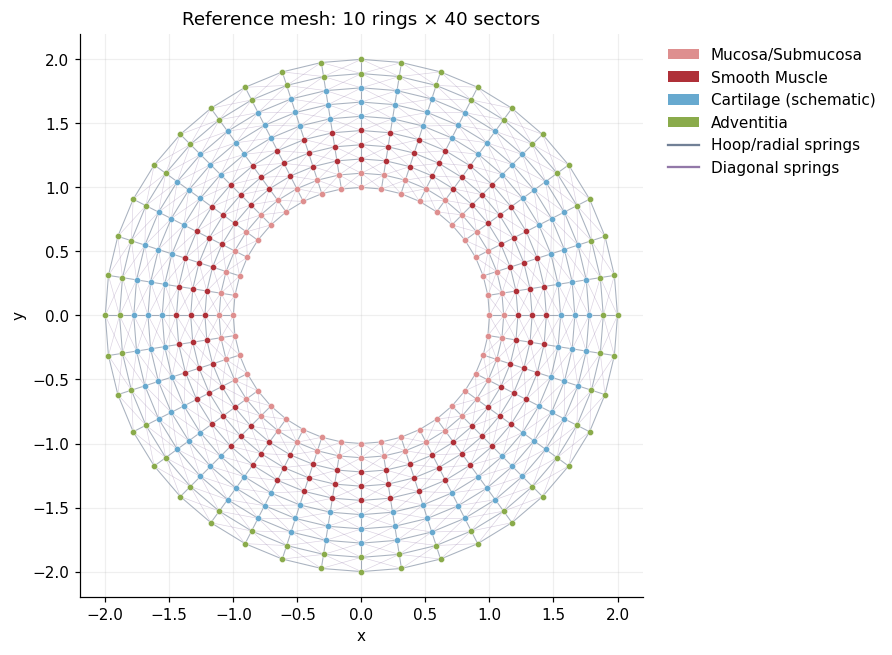

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})


class AirwayMesh:
    # Stable parameter keys are separate from labels used in figures.
    TISSUES = {
        "mucosa": ("Mucosa/Submucosa", "#de8f8f"),
        "muscle": ("Smooth Muscle", "#af3038"),
        "cartilage": ("Cartilage (schematic)", "#67a9cf"),
        "adventitia": ("Adventitia", "#8aab4b"),
    }

    def __init__(self, r_inner=1.0, r_outer=2.0, n_radial=10, n_circum=40):
        if not np.isfinite([r_inner, r_outer]).all() or not 0 < r_inner < r_outer:
            raise ValueError("Require finite radii with 0 < r_inner < r_outer.")
        for name, value, minimum in (("n_radial", n_radial, 2), ("n_circum", n_circum, 3)):
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(f"{name} must be an integer >= {minimum}.")
        self.r_inner, self.r_outer = float(r_inner), float(r_outer)
        self.n_radial, self.n_circum = int(n_radial), int(n_circum)
        tissue_indices = np.searchsorted([0.2, 0.5, 0.8], np.linspace(0, 1, self.n_radial), side="right")
        self.layer_ids = np.asarray(list(self.TISSUES))[tissue_indices]
        self.layer_map = [self.TISSUES[key] for key in self.layer_ids]
        self.generate_mesh()

    def generate_mesh(self):
        radii = np.linspace(self.r_inner, self.r_outer, self.n_radial)
        angles = np.arange(self.n_circum) * (2 * np.pi / self.n_circum)
        directions = np.column_stack((np.cos(angles), np.sin(angles)))
        self.nodes = radii[:, None, None] * directions[None, :, :]
        return self.nodes.copy()

    def connectivity(self, show_diagonal=True):
        edges, kinds = [], []
        for r in range(self.n_radial):
            for c in range(self.n_circum):
                i = r * self.n_circum + c
                j = r * self.n_circum + (c + 1) % self.n_circum
                edges.append((i, j))
                kinds.append("hoop")
                if r < self.n_radial - 1:
                    edges.append((i, i + self.n_circum))
                    kinds.append("radial")
                    if show_diagonal:
                        edges.extend([(i, j + self.n_circum), (j, i + self.n_circum)])
                        kinds.extend(["diagonal", "diagonal"])
        return np.asarray(edges, dtype=int), np.asarray(kinds)

    def plot(self, show_diagonal=True, positions=None, ax=None, legend=True, title=None):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 8), layout="constrained")
        nodes = self.nodes if positions is None else np.asarray(positions).reshape(self.nodes.shape)
        edges, kinds = self.connectivity(show_diagonal)
        segments = nodes.reshape(-1, 2)[edges]
        for kind, color, width, alpha in [("hoop", "#718096", 0.7, 0.6),
                                           ("radial", "#718096", 0.7, 0.6),
                                           ("diagonal", "#9278a8", 0.4, 0.35)]:
            ax.add_collection(LineCollection(segments[kinds == kind], colors=color,
                                            linewidths=width, alpha=alpha))
        for r, (_, color) in enumerate(self.layer_map):
            ax.scatter(*nodes[r].T, c=color, s=16, edgecolors="white", linewidths=0.25, zorder=3)
        if legend:
            handles = [Patch(facecolor=color, label=name) for name, color in dict(self.layer_map).items()]
            handles.append(Line2D([], [], color="#718096", label="Hoop/radial springs"))
            if show_diagonal:
                handles.append(Line2D([], [], color="#9278a8", label="Diagonal springs"))
            ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
        ax.set(aspect="equal", xlabel="x", ylabel="y", title=title or "Annular airway mesh")
        ax.autoscale()
        return ax


mesh = AirwayMesh()
mesh.plot(title=f"Reference mesh: {mesh.n_radial} rings × {mesh.n_circum} sectors")
# Optional export: mesh.plot().figure.savefig("airway_mesh.pdf", bbox_inches="tight")
plt.show()

## 2. Forces, constraints, and relaxation

For a spring joining nodes $i$ and $j$, let
$\mathbf{e}_{ij}=(\mathbf{x}_j-\mathbf{x}_i)/L_{ij}$. Its contribution to node $i$ is

$$
\mathbf{F}_{ij}=[k_{ij}(L_{ij}-L^0_{ij})+T_{ij}]\mathbf{e}_{ij},
\qquad \mathbf{F}_{ji}=-\mathbf{F}_{ij}.
$$

The rest length $L^0_{ij}$ comes from the reference mesh and remains unchanged
during perturbation or relaxation. Initially $T_{ij}=0$. Later, a prescribed
positive tension is applied only to hoop springs in the smooth-muscle rings.
These pair forces conserve total internal force and torque. Fixed outer nodes
supply reaction forces, so the free nodes alone need not have zero total force.

With a constant applied nodal force $\mathbf{f}_i$, the total potential is

$$
\Pi=\underbrace{\frac12\sum_{ij}k_{ij}(L_{ij}-L^0_{ij})^2}_{U_{\mathrm{elastic}}}
+\underbrace{\sum_{ij}T_{ij}(L_{ij}-L^0_{ij})}_{\text{prescribed-tension potential}}
-\sum_i\mathbf{f}_i\cdot(\mathbf{x}_i-\mathbf{x}_i^0).
$$

Each spring appears once in these sums. The tension potential is a mathematical
way to impose constant tension; it is not a model of muscle metabolism.
For free nodes, $\mathbf{F}_i=-\nabla_i\Pi$ and the overdamped update is

$$
\mathbf{x}_i^{n+1}=\mathbf{x}_i^n+\frac{\Delta t}{\gamma}\mathbf{F}_i^n.
$$

The initial numerical step is scaled by the largest sum of spring stiffnesses
incident on a node. Backtracking halves a proposed step if the total potential
does not decrease sufficiently. This is a relaxation algorithm; its time axis is
not a prediction of contraction speed. Outer nodes stay at their reference
positions. We stop when the largest **free-node force norm** is below `force_tol`,
and explicitly report a step-limit exit. A small displacement alone is not an
equilibrium check.

In [2]:
class AirwayModel:
    """Central-force springs with optional layer stiffnesses and muscle tension.

    stiffness sets all layer coefficients when layer_stiffness is None.
    Otherwise, supply a complete mapping using the keys in AirwayMesh.TISSUES;
    that mapping replaces the uniform coefficient. Diagonals retain their ratio.
    """

    def __init__(self, mesh, stiffness=50.0, diagonal_ratio=0.5, damping=1.0,
                 muscle_tension=0.0, *, layer_stiffness=None):
        values = [stiffness, diagonal_ratio, damping, muscle_tension]
        if not np.isfinite(values).all() or stiffness <= 0 or damping <= 0 or diagonal_ratio < 0 or muscle_tension < 0:
            raise ValueError("Require k, damping > 0 and diagonal_ratio, muscle_tension >= 0, all finite.")
        self.mesh = mesh
        self.reference = mesh.nodes.reshape(-1, 2).copy()
        self.positions = self.reference.copy()
        self.edges, self.kinds = mesh.connectivity(show_diagonal=diagonal_ratio > 0)
        self.i, self.j = self.edges.T
        self.rest_lengths = np.linalg.norm(self.reference[self.j] - self.reference[self.i], axis=1)
        if layer_stiffness is None:
            coefficients = {key: float(stiffness) for key in mesh.TISSUES}
        else:
            if not isinstance(layer_stiffness, dict) or set(layer_stiffness) != set(mesh.TISSUES):
                raise ValueError(f"layer_stiffness must specify exactly these keys: {', '.join(mesh.TISSUES)}.")
            coefficients = {}
            for key in mesh.TISSUES:
                value = layer_stiffness[key]
                if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
                    raise ValueError(f"Layer stiffness for {key} must be a finite positive number.")
                if not np.isfinite(value) or value <= 0:
                    raise ValueError(f"Layer stiffness for {key} must be a finite positive number.")
                coefficients[key] = float(value)
        self.layer_stiffness = coefficients  # Own copy; later caller edits do not change this model.
        self.ring_stiffness = np.array([coefficients[key] for key in mesh.layer_ids])
        node_stiffness = np.repeat(self.ring_stiffness, mesh.n_circum)
        low = np.minimum(node_stiffness[self.i], node_stiffness[self.j])
        high = np.maximum(node_stiffness[self.i], node_stiffness[self.j])
        # Harmonic mean 2*k_i*k_j/(k_i+k_j), evaluated without multiplying large coefficients.
        edge_stiffness = low / (0.5 + 0.5 * low / high)
        self.stiffness = edge_stiffness * np.where(self.kinds == "diagonal", diagonal_ratio, 1.0)
        self.fixed = np.zeros(len(self.reference), dtype=bool)
        self.fixed[-mesh.n_circum:] = True
        self.free = ~self.fixed
        self.damping = damping
        muscle_rings = mesh.layer_ids == "muscle"
        self.muscle_edges = (self.kinds == "hoop") & muscle_rings[self.i // mesh.n_circum]
        if muscle_tension > 0 and not self.muscle_edges.any():
            raise ValueError("This radial mesh has no smooth-muscle ring; increase n_radial.")
        self.tensions = muscle_tension * self.muscle_edges
        incident_k = np.bincount(self.i, weights=self.stiffness, minlength=len(self.reference))
        incident_k += np.bincount(self.j, weights=self.stiffness, minlength=len(self.reference))
        self.default_dt = 0.8 * damping / (2 * incident_k.max())
        self.initial_area = self.lumen_area(self.reference)

    def spring_state(self, positions=None):
        x = self.positions if positions is None else np.asarray(positions, dtype=float)
        if x.shape != self.reference.shape or not np.isfinite(x).all():
            raise ValueError("Positions must be finite with shape (number_of_nodes, 2).")
        vectors = x[self.j] - x[self.i]
        lengths = np.linalg.norm(vectors, axis=1)
        if np.any(lengths <= 1e-10 * self.rest_lengths.min()):
            raise ValueError("A spring collapsed; reduce the load or perturbation.")
        return vectors, lengths

    def internal_forces(self, positions=None):
        vectors, lengths = self.spring_state(positions)
        magnitudes = self.stiffness * (lengths - self.rest_lengths) + self.tensions
        pair_forces = (magnitudes / lengths)[:, None] * vectors
        forces = np.zeros_like(self.reference)
        # bincount sums contributions even when many springs share one node.
        for axis in range(2):
            forces[:, axis] = np.bincount(self.i, weights=pair_forces[:, axis], minlength=len(forces))
            forces[:, axis] -= np.bincount(self.j, weights=pair_forces[:, axis], minlength=len(forces))
        return forces

    def elastic_energy(self, positions=None):
        _, lengths = self.spring_state(positions)
        return float(0.5 * np.sum(self.stiffness * (lengths - self.rest_lengths) ** 2))

    def potential(self, positions, external):
        _, lengths = self.spring_state(positions)
        extension = lengths - self.rest_lengths
        return float(0.5 * np.sum(self.stiffness * extension ** 2)
                     + np.dot(self.tensions, extension)
                     - np.sum(external * (positions - self.reference)))

    def lumen_area(self, positions=None):
        x = self.positions if positions is None else positions
        ring = x[:self.mesh.n_circum]
        following = np.roll(ring, -1, axis=0)
        return float(abs(np.sum(ring[:, 0] * following[:, 1] - ring[:, 1] * following[:, 0])) / 2)

    def constriction(self):
        return 100 * (1 - self.lumen_area() / self.initial_area)

    def radial_load(self, magnitude):
        """Equal reference-radial dead loads on lumen nodes; not a pressure law."""
        if not np.isfinite(magnitude):
            raise ValueError("Load magnitude must be finite.")
        loads = np.zeros_like(self.reference)
        inner = self.reference[:self.mesh.n_circum]
        loads[:self.mesh.n_circum] = magnitude * inner / np.linalg.norm(inner, axis=1)[:, None]
        return loads

    def relax(self, external=None, dt=None, max_steps=30000, force_tol=1e-7, save_every=100):
        loads = np.zeros_like(self.reference) if external is None else np.array(external, dtype=float, copy=True)
        if loads.shape != self.reference.shape or not np.isfinite(loads).all():
            raise ValueError("External forces must be finite and match the position array.")
        step_size = self.default_dt if dt is None else float(dt)
        if not np.isfinite([step_size, force_tol]).all() or step_size <= 0 or force_tol <= 0:
            raise ValueError("dt and force_tol must be finite and positive.")
        for name, value, minimum in (("max_steps", max_steps, 0), ("save_every", save_every, 1)):
            if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(f"{name} must be an integer >= {minimum}.")
        self.positions[self.fixed] = self.reference[self.fixed]
        history = {name: [] for name in ("time", "positions", "elastic_energy", "potential", "residual", "area")}
        elapsed, backtracks = 0.0, 0
        for step in range(max_steps + 1):
            forces = self.internal_forces() + loads
            residual = float(np.linalg.norm(forces[self.free], axis=1).max())
            total = self.potential(self.positions, loads)
            converged = residual <= force_tol
            if step % save_every == 0 or converged or step == max_steps:
                history["time"].append(elapsed)
                history["positions"].append(self.positions.copy())
                history["elastic_energy"].append(self.elastic_energy())
                history["potential"].append(total)
                history["residual"].append(residual)
                history["area"].append(self.lumen_area())
            if converged or step == max_steps:
                break
            forces[self.fixed] = 0.0
            squared_force = float(np.sum(forces ** 2))
            # Keep accepted steps at or below the caller's chosen step size.
            for attempt in range(40):
                trial = self.positions + step_size * forces / self.damping
                try:
                    trial_energy = self.potential(trial, loads)
                except ValueError:
                    trial_energy = np.inf
                allowance = 1e-14 * max(1.0, abs(total))
                if trial_energy <= total - 1e-4 * step_size * squared_force / self.damping + allowance:
                    break
                step_size *= 0.5
                backtracks += 1
            else:
                raise RuntimeError("Backtracking failed to find an energy-decreasing step.")
            self.positions = trial
            elapsed += step_size
        result = {name: np.asarray(values) for name, values in history.items()}
        result.update(converged=converged, steps=step, backtracks=backtracks,
                      accepted_dt=step_size, reason="force tolerance" if converged else "step limit")
        return result


def report(label, model, result):
    print(f"{label}: {result['reason']}; {result['steps']:,} steps; "
          f"max free force = {result['residual'][-1]:.2e}; "
          f"lumen area change = {100 * (result['area'][-1] / model.initial_area - 1):+.3f}%")


def check_relaxation(model, result, require_converged=True):
    assert np.isfinite(result["positions"]).all(), "Nonfinite trajectory"
    np.testing.assert_allclose(result["positions"][:, model.fixed],
                               np.broadcast_to(model.reference[model.fixed], result["positions"][:, model.fixed].shape),
                               rtol=0, atol=0)
    assert np.max(np.diff(result["potential"]), initial=0) <= 1e-10, "Potential increased"
    if require_converged:
        assert result["converged"], f"Not equilibrated: {result['reason']}"

## 3. Check the force implementation

Before running experiments, verify the edge counts and seam, the undeformed
polygon area, internal force/torque balance, and the sign and magnitude of the
force against a central finite difference of the potential. The gradient check
includes passive springs, active tension, and external loads.

In [3]:
edges, kinds = mesh.connectivity()
nr, nc = mesh.n_radial, mesh.n_circum
assert (kinds == "hoop").sum() == nr * nc
assert (kinds == "radial").sum() == (nr - 1) * nc
assert (kinds == "diagonal").sum() == 2 * (nr - 1) * nc
assert len(np.unique(np.sort(edges, axis=1), axis=0)) == len(edges)
assert any(np.array_equal(edge, [nc - 1, 0]) for edge in edges)

probe = AirwayModel(mesh, muscle_tension=0.6)
expected_area = nc * mesh.r_inner ** 2 * np.sin(2 * np.pi / nc) / 2
np.testing.assert_allclose(probe.initial_area, expected_area, rtol=1e-14)
rng = np.random.default_rng(42)
probe.positions[probe.free] += rng.normal(scale=0.002, size=probe.positions[probe.free].shape)
internal = probe.internal_forces()
np.testing.assert_allclose(internal.sum(axis=0), 0, atol=1e-12)
torque = np.sum(probe.positions[:, 0] * internal[:, 1] - probe.positions[:, 1] * internal[:, 0])
assert abs(torque) < 1e-12
loads = probe.radial_load(0.03)
direction = rng.normal(size=probe.positions.shape)
direction[probe.fixed] = 0
direction /= np.linalg.norm(direction)
epsilon = 1e-6
numerical_derivative = (probe.potential(probe.positions + epsilon * direction, loads)
                        - probe.potential(probe.positions - epsilon * direction, loads)) / (2 * epsilon)
force_derivative = -np.sum((internal + loads) * direction)
np.testing.assert_allclose(numerical_derivative, force_derivative, rtol=1e-6, atol=1e-8)
print(f"Topology, polygon area, force/torque balance, and energy gradient: PASS ({len(edges):,} springs)")

Topology, polygon area, force/torque balance, and energy gradient: PASS (1,480 springs)


## 4. Passive experiment: zero force

At the reference geometry, every passive spring is at its rest length. With no
applied force, the model should already satisfy the equilibrium tolerance,
with zero energy and no movement. A separate perturbed one-step run checks that
the solver reports an unfinished relaxation instead of claiming convergence.

In [4]:
resting = AirwayModel(mesh)
rest_result = resting.relax()
np.testing.assert_array_equal(resting.positions, resting.reference)
assert resting.elastic_energy() == 0
assert rest_result["steps"] == 0
check_relaxation(resting, rest_result)
report("Unloaded reference", resting, rest_result)

unfinished = AirwayModel(mesh)
unfinished.positions[0, 0] += 0.01
unfinished_result = unfinished.relax(max_steps=1)
assert not unfinished_result["converged"] and unfinished_result["reason"] == "step limit"
print("Zero-force stability and step-limit reporting: PASS")

Unloaded reference: force tolerance; 0 steps; max free force = 0.00e+00; lumen area change = +0.000%
Zero-force stability and step-limit reporting: PASS


## 5. Passive experiment: uniform radial loading

Each lumen node receives the same outward force magnitude along its **reference**
radial direction. The outer ring remains fixed. This is a constant nodal-load
experiment, not a pressure boundary condition: a pressure model would need forces
weighted by boundary segment length and updated normals.

Rotational symmetry should be preserved, the lumen should expand, and fixed-node
reactions should balance the external loads. Elastic energy can increase as the
load does work; it is the **total potential** that decreases during relaxation.

Radial load: force tolerance; 3,172 steps; max free force = 9.97e-08; lumen area change = +2.089%
Radial symmetry error: 6.66e-16; boundary/load balance: PASS


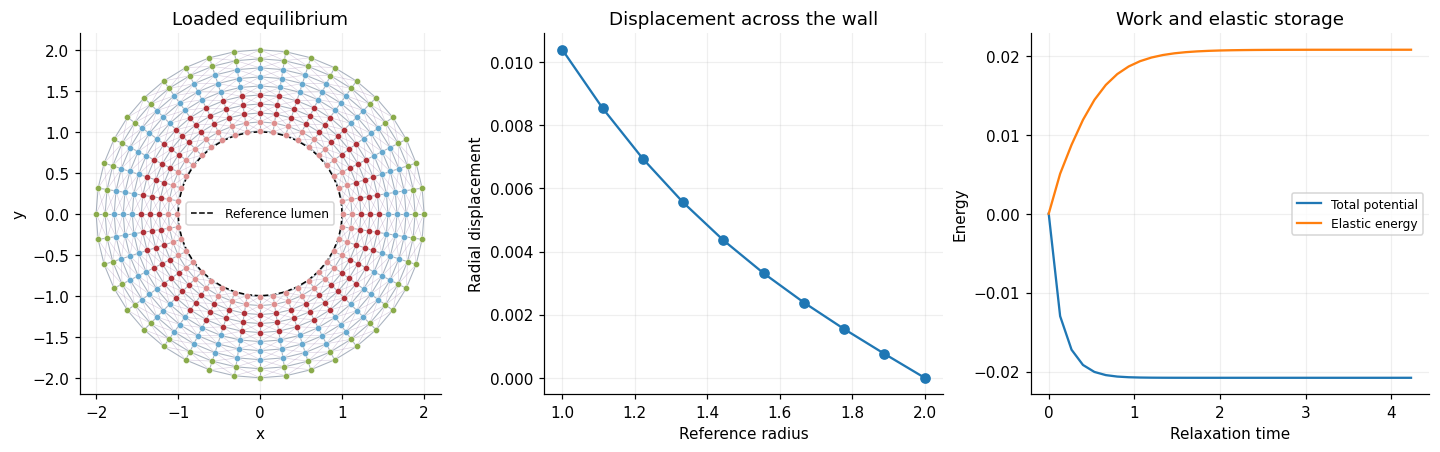

In [5]:
expanded = AirwayModel(mesh)
outward_load = expanded.radial_load(0.1)
expansion_result = expanded.relax(external=outward_load)
check_relaxation(expanded, expansion_result)
report("Radial load", expanded, expansion_result)
assert expanded.lumen_area() > expanded.initial_area
rings = expanded.positions.reshape(nr, nc, 2)
radii = np.linalg.norm(rings, axis=2)
symmetry_error = np.ptp(radii, axis=1).max()
assert symmetry_error < 1e-10
reference_directions = expanded.reference / np.linalg.norm(expanded.reference, axis=1)[:, None]
tangents = np.column_stack((-reference_directions[:, 1], reference_directions[:, 0]))
assert np.abs(np.sum(expanded.positions * tangents, axis=1)).max() < 1e-10
net_force = expanded.internal_forces() + outward_load
reactions = -net_force[expanded.fixed]
np.testing.assert_allclose(reactions.sum(axis=0) + outward_load.sum(axis=0), 0, atol=1e-6)
print(f"Radial symmetry error: {symmetry_error:.2e}; boundary/load balance: PASS")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
expanded.mesh.plot(positions=expanded.positions, ax=axes[0], legend=False, title="Loaded equilibrium")
initial_lumen = np.vstack([expanded.reference[:nc], expanded.reference[0]])
axes[0].plot(*initial_lumen.T, "k--", lw=1, label="Reference lumen")
axes[0].legend(fontsize=8)
axes[1].plot(np.linspace(mesh.r_inner, mesh.r_outer, nr), radii.mean(axis=1) - np.linspace(mesh.r_inner, mesh.r_outer, nr), "o-")
axes[1].set(xlabel="Reference radius", ylabel="Radial displacement", title="Displacement across the wall")
axes[2].plot(expansion_result["time"], expansion_result["potential"], label="Total potential")
axes[2].plot(expansion_result["time"], expansion_result["elastic_energy"], label="Elastic energy")
axes[2].set(xlabel="Relaxation time", ylabel="Energy", title="Work and elastic storage")
axes[2].legend(fontsize=8)
plt.show()

## 6. Passive experiment: tangential perturbation

Rotate one interior ring by 0.04 radians, keeping its radius and hoop lengths
unchanged, then remove the perturbing constraint and relax without external load.
Compare networks with and without diagonal springs at the same relaxation time.
An equilibrated run stops early; the comparison uses the shorter recorded duration.

Near the reference state, a tangential displacement changes the length of a
radial spring only at second order. Its energy therefore starts at fourth order
in that displacement. Diagonal springs change length at first order and add
second-order shear energy. The network without diagonals can still resist a
finite perturbation; it is not correct to promise that it must collapse.

The small-angle energy check below isolates that distinction. For the finite
perturbation, we check that adding diagonals produces more restoring energy and
less residual tangential displacement over the observation window.

Energy ratios when a small rotation doubles: 4.000 with diagonals, 16.000 without


With diagonals: force tolerance; 4,572 steps; max free force = 9.99e-08; lumen area change = +0.000%


Without diagonals: step limit; 12,000 steps; max free force = 2.63e-04; lumen area change = +0.097%
At time 6.096, tangential RMS displacement is 4.02e-08 with diagonals vs 1.03e-02 without.


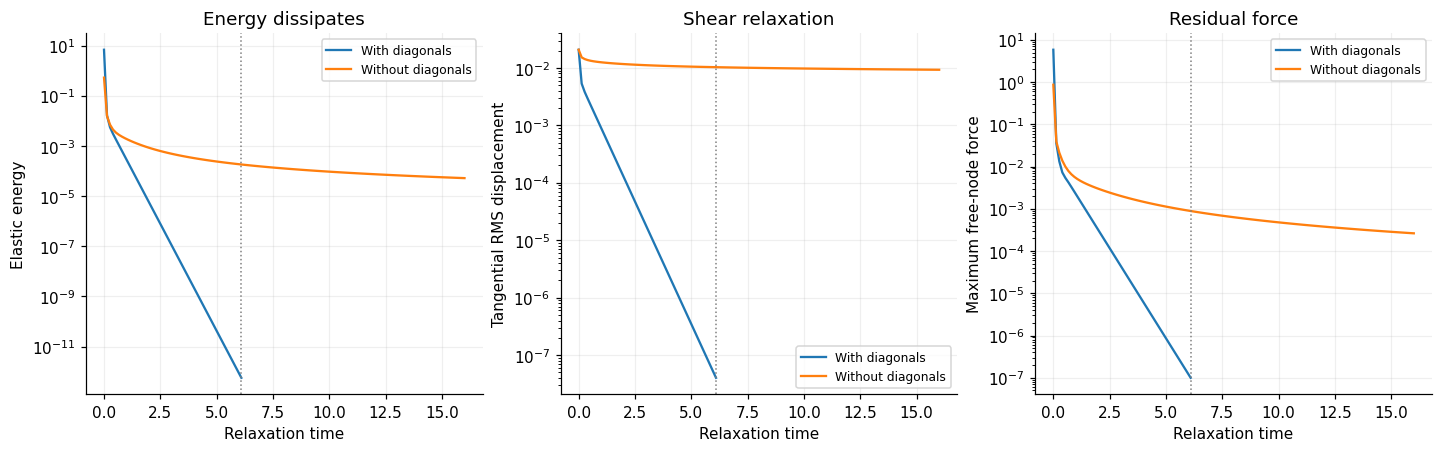

In [6]:
def rotate_ring(model, ring_index, angle):
    rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    selected = slice(ring_index * model.mesh.n_circum, (ring_index + 1) * model.mesh.n_circum)
    model.positions[selected] = model.reference[selected] @ rotation.T


ring_index = nr // 2
shear_models = [AirwayModel(mesh, diagonal_ratio=ratio) for ratio in (0.5, 0.0)]
small_angle_energies = []
for model in shear_models:
    energies = []
    for angle in (1e-4, 2e-4):
        rotate_ring(model, ring_index, angle)
        energies.append(model.elastic_energy())
    small_angle_energies.append(energies)
ratios = np.array(small_angle_energies)[:, 1] / np.array(small_angle_energies)[:, 0]
np.testing.assert_allclose(ratios, [4, 16], rtol=0.01)
print(f"Energy ratios when a small rotation doubles: {ratios[0]:.3f} with diagonals, {ratios[1]:.3f} without")

common_dt = min(model.default_dt for model in shear_models)
shear_results = []
for model, label in zip(shear_models, ["With diagonals", "Without diagonals"]):
    rotate_ring(model, ring_index, 0.04)
    result = model.relax(dt=common_dt, max_steps=12000)
    check_relaxation(model, result, require_converged=False)
    shear_results.append(result)
    report(label, model, result)
assert shear_results[0]["elastic_energy"][0] > shear_results[1]["elastic_energy"][0]
assert all(result["backtracks"] == 0 for result in shear_results), "Use matched times if backtracking occurs"

def tangential_rms(model, result):
    reference_radius = np.linalg.norm(model.reference, axis=1)
    directions = model.reference / reference_radius[:, None]
    tangents = np.column_stack((-directions[:, 1], directions[:, 0]))
    displacement = result["positions"] - model.reference
    tangential = np.sum(displacement * tangents[None, :, :], axis=2)
    return np.sqrt(np.mean(tangential[:, model.free] ** 2, axis=1))

shear_motion = [tangential_rms(model, result) for model, result in zip(shear_models, shear_results)]
comparison_time = min(result["time"][-1] for result in shear_results)
compared_motion = [np.interp(comparison_time, result["time"], motion)
                   for result, motion in zip(shear_results, shear_motion)]
assert compared_motion[0] < compared_motion[1]
print(f"At time {comparison_time:.3f}, tangential RMS displacement is "
      f"{compared_motion[0]:.2e} with diagonals vs {compared_motion[1]:.2e} without.")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for result, motion, label in zip(shear_results, shear_motion, ["With diagonals", "Without diagonals"]):
    axes[0].semilogy(result["time"], np.maximum(result["elastic_energy"], 1e-20), label=label)
    axes[1].semilogy(result["time"], np.maximum(motion, 1e-20), label=label)
    axes[2].semilogy(result["time"], np.maximum(result["residual"], 1e-20), label=label)
axes[0].set(xlabel="Relaxation time", ylabel="Elastic energy", title="Energy dissipates")
axes[1].set(xlabel="Relaxation time", ylabel="Tangential RMS displacement", title="Shear relaxation")
axes[2].set(xlabel="Relaxation time", ylabel="Maximum free-node force", title="Residual force")
for ax in axes:
    ax.axvline(comparison_time, color="gray", ls=":", lw=1)
    ax.legend(fontsize=8)
plt.show()

## 7. Active smooth-muscle contraction

Prescribe $T_{ij}=aT_{\max}$ on each hoop spring in the schematic muscle region,
where $0\leq a\leq1$ is activation. All other springs have $T_{ij}=0$. Each active
edge pulls its endpoints toward one another along its current direction. Summed
around a ring, these forces pull inward while retaining zero net internal force
and torque.

This is an imposed constant-tension model. It has no calcium signalling,
force–length or force–velocity relation, stiffness sensing, or Hai–Murphy
cross-bridge kinetics. Muscle-ring selection sets the active-force location independently of the
passive layer stiffnesses. This sweep retains the uniform passive baseline;
section 9 changes the passive layer coefficients at the same muscle tension.

At each activation, start from the same unloaded mesh and relax to the same
force tolerance. Lumen area is computed using the shoelace formula on the inner
polygon, and constriction is $100(1-A/A_0)$; positive values mean narrowing.
The figure shows actual displacements, without magnification.

Activation 0.00: force tolerance; 0 steps; max free force = 0.00e+00; lumen area change = +0.000%


Activation 0.25: force tolerance; 3,338 steps; max free force = 9.96e-08; lumen area change = -2.641%


Activation 0.50: force tolerance; 3,532 steps; max free force = 9.97e-08; lumen area change = -5.261%


Activation 0.75: force tolerance; 3,653 steps; max free force = 9.97e-08; lumen area change = -7.859%


Activation 1.00: force tolerance; 3,744 steps; max free force = 9.99e-08; lumen area change = -10.436%


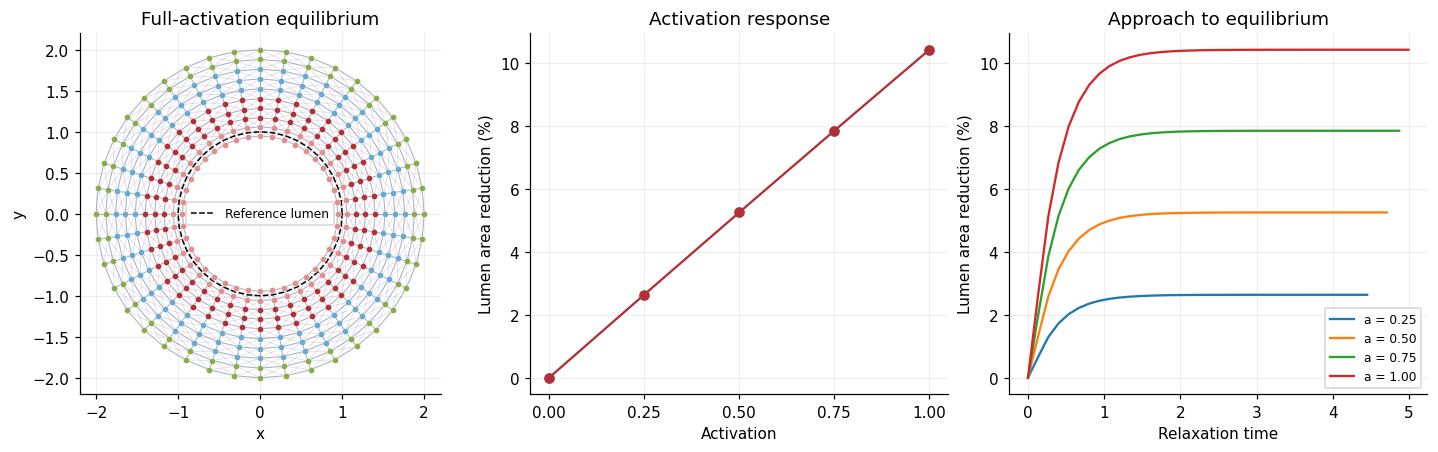

In [7]:
activations = np.linspace(0, 1, 5)
maximum_tension = 2.0  # Force per muscle hoop spring, independent of spring stiffness.
active_models, active_results, narrowing = [], [], []
for activation in activations:
    model = AirwayModel(mesh, muscle_tension=activation * maximum_tension)
    result = model.relax()
    check_relaxation(model, result)
    active_models.append(model)
    active_results.append(result)
    narrowing.append(model.constriction())
    report(f"Activation {activation:.2f}", model, result)
narrowing = np.asarray(narrowing)
np.testing.assert_array_equal(active_models[0].positions, resting.positions)
assert narrowing[0] == 0 and np.all(np.diff(narrowing) > 0)

contracted, contraction_result = active_models[-1], active_results[-1]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
contracted.mesh.plot(positions=contracted.positions, ax=axes[0], legend=False, title="Full-activation equilibrium")
axes[0].plot(*initial_lumen.T, "k--", lw=1, label="Reference lumen")
axes[0].legend(fontsize=8)
axes[1].plot(activations, narrowing, "o-", color="#af3038")
axes[1].set(xlabel="Activation", ylabel="Lumen area reduction (%)", title="Activation response", xticks=activations)
for activation, model, result in zip(activations[1:], active_models[1:], active_results[1:]):
    axes[2].plot(result["time"], 100 * (1 - result["area"] / model.initial_area), label=f"a = {activation:.2f}")
axes[2].set(xlabel="Relaxation time", ylabel="Lumen area reduction (%)", title="Approach to equilibrium")
axes[2].legend(fontsize=8)
plt.show()

## 8. Numerical checks and interpretation

Repeat full activation with half the numerical step. The equilibrium geometry
should agree within the force-tolerance error. Separately, doubling every spring
stiffness and the applied muscle tension multiplies all internal forces by two,
so it should leave the equilibrium geometry unchanged. These are checks on the
implementation, not experimental validation of tissue mechanics.

In [8]:
refined = AirwayModel(mesh, muscle_tension=maximum_tension)
refined_result = refined.relax(dt=refined.default_dt / 2, max_steps=60000)
check_relaxation(refined, refined_result)
geometry_difference = np.linalg.norm(refined.positions - contracted.positions, axis=1).max()
assert geometry_difference < 1e-6
assert abs(refined.constriction() - contracted.constriction()) < 1e-4

scaled = AirwayModel(mesh, stiffness=100.0, muscle_tension=2 * maximum_tension)
scaled_result = scaled.relax(force_tol=2e-7)
check_relaxation(scaled, scaled_result)
np.testing.assert_allclose(scaled.positions, contracted.positions, rtol=0, atol=1e-7)
print(f"Half-step equilibrium difference: {geometry_difference:.2e}")
print(f"Full-activation lumen narrowing: {contracted.constriction():.3f}%")
print("Passive checks, active-force sweep, time-step refinement, and force/stiffness scaling: PASS")

Half-step equilibrium difference: 1.27e-11
Full-activation lumen narrowing: 10.436%
Passive checks, active-force sweep, time-step refinement, and force/stiffness scaling: PASS


The completed experiments test distinct properties: zero load preserves the rest
mesh; symmetric radial loading expands the lumen without breaking rotational
symmetry; diagonal springs give stronger small-displacement shear resistance;
and prescribed circumferential muscle tension narrows the lumen. The plots and
reported residuals show which runs reached equilibrium. A shear comparison that
ends at the step limit is a finite-time observation, not an equilibrium result.

The area changes depend on force relative to stiffness, geometry, boundary
constraints, and mesh resolution. Refining the mesh while keeping each spring's
stiffness and tension fixed changes the physical model; the half-step check above
does **not** establish mesh independence. The model also lacks incompressibility,
contact, protection against element inversion at large deformation, pressure
loading, and calibrated layer properties. Its reliable scope here is the modest
deformations exercised by these checks. Overdamped node motion is a chosen
relaxation rule rather than a measured tissue constitutive law.

The next section adds layer stiffnesses while preserving the checks above.
Stiffness–activation sweeps, mesh-scaled material parameters, and time-dependent
muscle kinetics are subsequent phases in the development checklist.

## 9. Phase 1 — independent passive layer stiffnesses

`layer_stiffness` supplies the passive spring coefficients for `mucosa`, `muscle`,
`cartilage`, and `adventitia`. These are dimensionless spring stiffnesses, not
Young's moduli. Omit the mapping to retain the scalar `stiffness` baseline. When
provided, the mapping must contain all four keys with finite positive values;
it replaces the scalar coefficient. This avoids silently accepting a misspelled
layer or filling in an omitted material value.

For endpoints with layer coefficients $k_i$ and $k_j$, use

$$
k_{ij}^{\mathrm{base}}=\left(\frac{1}{2k_i}+\frac{1}{2k_j}\right)^{-1}
=\frac{2k_i k_j}{k_i+k_j}.
$$

This **chosen interface rule** treats each spring as two equal-length material
halves in series, with the boundary at its midpoint. Each half has twice its
material's whole-spring stiffness, and the two compliances add. Within a layer,
$k_i=k_j$ recovers that layer's coefficient. Across a boundary, both materials
contribute. Hoop and radial springs use $k_{ij}^{\mathrm{base}}$; diagonals use
`diagonal_ratio` times that value. This is a discrete material assignment; a
continuum interpretation and mesh scaling remain phase 3 work.

The profile below is an illustrative heterogeneous example, not a fitted tissue
parameter set. Active tension is unchanged: altering passive muscle stiffness
does not alter the number, location, or tension of active edges. Each simulation
constructs its own copy of the layer coefficients and reference positions.

In [9]:
# Edit these four values to explore passive material differences.
layer_stiffness = {
    "mucosa": 25.0,
    "muscle": 50.0,
    "cartilage": 150.0,
    "adventitia": 75.0,
}
uniform_layer_stiffness = {key: 50.0 for key in mesh.TISSUES}
print(f"{'Layer':<25} {'Stiffness':>10} {'Rings':>8}")
for key, coefficient in layer_stiffness.items():
    print(f"{mesh.TISSUES[key][0]:<25} {coefficient:>10.1f} {(mesh.layer_ids == key).sum():>8}")

Layer                      Stiffness    Rings
Mucosa/Submucosa                25.0        2
Smooth Muscle                   50.0        3
Cartilage (schematic)          150.0        3
Adventitia                      75.0        2


### Validate the material assignment

Check a hand-calculated interface: the mucosa–muscle boundary with coefficients
25 and 50 must have radial stiffness $100/3$ and diagonal stiffness $50/3$.
Changing only the muscle coefficient must leave every non-muscle-connected spring
unchanged and preserve active tension and rest lengths. Check the explicit uniform
mapping against the scalar baseline before testing the heterogeneous model's
rest state, force/torque balance, and energy gradient.

In [10]:
# Invalid or incomplete material specifications must fail before any relaxation.
bad_profiles = [
    {key: value for key, value in layer_stiffness.items() if key != "muscle"},
    dict(layer_stiffness, muscle_typo=50.0),
    *[dict(layer_stiffness, muscle=value) for value in (0.0, -1.0, np.nan, np.inf, True, "50")],
]
for profile in bad_profiles:
    try:
        AirwayModel(mesh, layer_stiffness=profile)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid layer stiffness was accepted")

uniform_explicit = AirwayModel(mesh, layer_stiffness=uniform_layer_stiffness,
                              muscle_tension=maximum_tension)
np.testing.assert_array_equal(uniform_explicit.stiffness, contracted.stiffness)
np.testing.assert_array_equal(uniform_explicit.tensions, contracted.tensions)
np.testing.assert_allclose(uniform_explicit.internal_forces(probe.positions),
                           contracted.internal_forces(probe.positions), rtol=0, atol=0)
assert uniform_explicit.elastic_energy(probe.positions) == contracted.elastic_energy(probe.positions)

heterogeneous = AirwayModel(mesh, layer_stiffness=layer_stiffness, muscle_tension=maximum_tension)
node_layers = np.repeat(mesh.layer_ids, nc)
endpoint_layers = node_layers[heterogeneous.edges]
interface = ((endpoint_layers[:, 0] == "mucosa") & (endpoint_layers[:, 1] == "muscle"))
assert (interface & (heterogeneous.kinds == "radial")).sum() == nc
assert (interface & (heterogeneous.kinds == "diagonal")).sum() == 2 * nc
# Use a separate fixed profile so this exact arithmetic check survives edits to the example.
interface_profile = dict(uniform_layer_stiffness, mucosa=25.0)
interface_model = AirwayModel(mesh, layer_stiffness=interface_profile)
np.testing.assert_allclose(interface_model.stiffness[interface & (interface_model.kinds == "radial")], 100 / 3)
np.testing.assert_allclose(interface_model.stiffness[interface & (interface_model.kinds == "diagonal")], 50 / 3)

muscle_changed = AirwayModel(mesh, layer_stiffness=dict(layer_stiffness, muscle=2 * layer_stiffness["muscle"]),
                            muscle_tension=maximum_tension)
touches_muscle = np.any(endpoint_layers == "muscle", axis=1)
np.testing.assert_array_equal(muscle_changed.stiffness[~touches_muscle], heterogeneous.stiffness[~touches_muscle])
assert np.all(muscle_changed.stiffness[touches_muscle] > heterogeneous.stiffness[touches_muscle])
np.testing.assert_array_equal(muscle_changed.rest_lengths, heterogeneous.rest_lengths)
np.testing.assert_array_equal(muscle_changed.tensions, heterogeneous.tensions)
passed_profile = layer_stiffness.copy()
copied_model = AirwayModel(mesh, layer_stiffness=passed_profile)
passed_profile["muscle"] *= 2
assert copied_model.layer_stiffness == layer_stiffness

layered_rest = AirwayModel(mesh, layer_stiffness=layer_stiffness)
layered_rest_result = layered_rest.relax()
check_relaxation(layered_rest, layered_rest_result)
np.testing.assert_array_equal(layered_rest.positions, layered_rest.reference)
assert layered_rest.elastic_energy() == 0 and layered_rest_result["steps"] == 0

# An asymmetric perturbation exercises interface springs as well as within-layer springs.
rng_layered = np.random.default_rng(123)
perturbed = heterogeneous.reference.copy()
perturbed[heterogeneous.free] += rng_layered.normal(scale=0.002, size=perturbed[heterogeneous.free].shape)
internal_layered = heterogeneous.internal_forces(perturbed)
np.testing.assert_allclose(internal_layered.sum(axis=0), 0, atol=1e-12)
layered_torque = np.sum(perturbed[:, 0] * internal_layered[:, 1] - perturbed[:, 1] * internal_layered[:, 0])
assert abs(layered_torque) < 1e-12
layered_loads = heterogeneous.radial_load(0.03)
layered_direction = rng_layered.normal(size=perturbed.shape)
layered_direction[heterogeneous.fixed] = 0
layered_direction /= np.linalg.norm(layered_direction)
layered_gradient = (heterogeneous.potential(perturbed + epsilon * layered_direction, layered_loads)
                    - heterogeneous.potential(perturbed - epsilon * layered_direction, layered_loads)) / (2 * epsilon)
np.testing.assert_allclose(layered_gradient, -np.sum((internal_layered + layered_loads) * layered_direction),
                           rtol=1e-6, atol=1e-8)
print("Material validation, uniform mapping, interfaces, independent controls, rest stability, and force/energy checks: PASS")

Material validation, uniform mapping, interfaces, independent controls, rest stability, and force/energy checks: PASS


### Compare contraction at the same activation

Relax both the explicit uniform mapping and the heterogeneous example at full
activation ($T_{\max}=2$ per muscle hoop spring). Check the uniform equilibrium
against section 7, then check convergence, fixed boundaries, and rotational
symmetry for the heterogeneous wall. The profiles share geometry, muscle tension,
and diagonal ratio; only passive material coefficients differ.

The first plot shows the assigned ring coefficients before interface averaging
and the diagonal factor. The other plots compare the actual inner boundary and
mean radial displacement across the wall. A follow-up run halves the numerical
step to verify the heterogeneous equilibrium. The multidimensional parameter
sweep is reserved for phase 2.

Explicit uniform layers: force tolerance; 3,744 steps; max free force = 9.99e-08; lumen area change = -10.436%


Heterogeneous layers: force tolerance; 9,527 steps; max free force = 9.99e-08; lumen area change = -8.529%


Heterogeneous half-step equilibrium difference: 4.57e-12
Lumen narrowing: uniform 10.436%, heterogeneous 8.529%


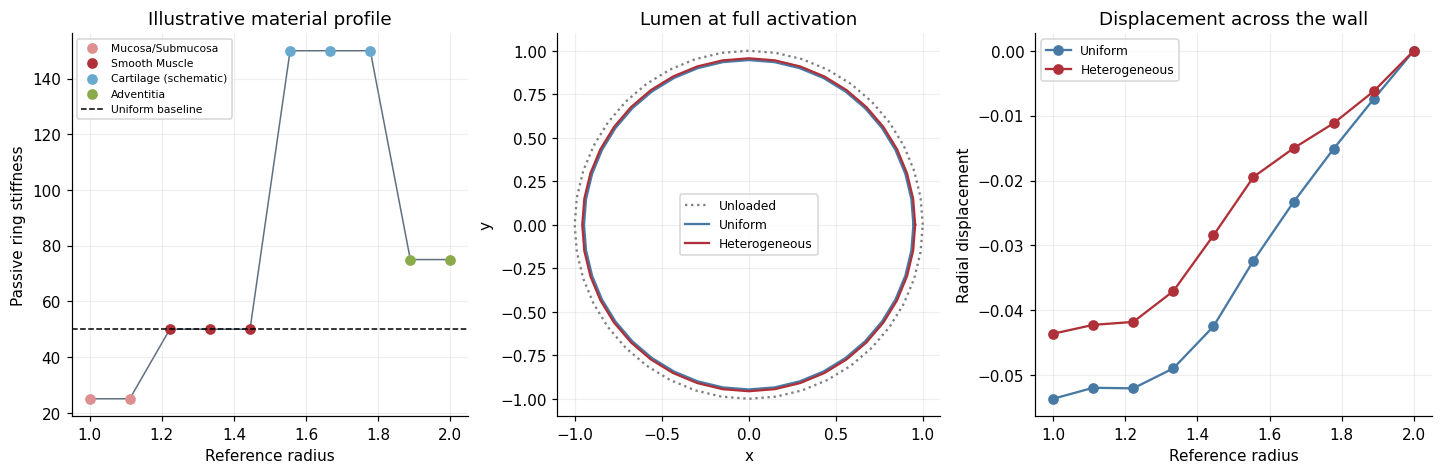

Phase 1 checks: PASS


In [11]:
uniform_explicit_result = uniform_explicit.relax()
check_relaxation(uniform_explicit, uniform_explicit_result)
np.testing.assert_allclose(uniform_explicit.positions, contracted.positions, rtol=0, atol=1e-10)
report("Explicit uniform layers", uniform_explicit, uniform_explicit_result)

layered_result = heterogeneous.relax(max_steps=60000)
check_relaxation(heterogeneous, layered_result)
report("Heterogeneous layers", heterogeneous, layered_result)
layered_radii = np.linalg.norm(heterogeneous.positions.reshape(nr, nc, 2), axis=2)
assert np.ptp(layered_radii, axis=1).max() < 1e-10
assert np.abs(np.sum(heterogeneous.positions * tangents, axis=1)).max() < 1e-10
assert heterogeneous.constriction() > 0

layered_refined = AirwayModel(mesh, layer_stiffness=layer_stiffness, muscle_tension=maximum_tension)
layered_refined_result = layered_refined.relax(dt=layered_refined.default_dt / 2, max_steps=120000)
check_relaxation(layered_refined, layered_refined_result)
layered_step_error = np.linalg.norm(layered_refined.positions - heterogeneous.positions, axis=1).max()
assert layered_step_error < 1e-6
assert abs(layered_refined.constriction() - heterogeneous.constriction()) < 1e-4
print(f"Heterogeneous half-step equilibrium difference: {layered_step_error:.2e}")
print(f"Lumen narrowing: uniform {contracted.constriction():.3f}%, heterogeneous {heterogeneous.constriction():.3f}%")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
reference_radii = np.linspace(mesh.r_inner, mesh.r_outer, nr)
axes[0].plot(reference_radii, heterogeneous.ring_stiffness, color="#607080", lw=1, zorder=1)
for key, (label, color) in mesh.TISSUES.items():
    selected = mesh.layer_ids == key
    axes[0].scatter(reference_radii[selected], heterogeneous.ring_stiffness[selected],
                    color=color, label=label, zorder=2)
axes[0].axhline(50, color="black", ls="--", lw=1, label="Uniform baseline")
axes[0].set(xlabel="Reference radius", ylabel="Passive ring stiffness", title="Illustrative material profile")
axes[0].legend(fontsize=7, loc="upper left")

axes[1].plot(*initial_lumen.T, color="#7f7f7f", ls=":", label="Unloaded")
for model, label, color in [(contracted, "Uniform", "#4779a5"), (heterogeneous, "Heterogeneous", "#af3038")]:
    lumen = np.vstack([model.positions[:nc], model.positions[0]])
    axes[1].plot(*lumen.T, color=color, label=label)
    current_radii = np.linalg.norm(model.positions.reshape(nr, nc, 2), axis=2)
    axes[2].plot(reference_radii, current_radii.mean(axis=1) - reference_radii, "o-", color=color, label=label)
axes[1].set(aspect="equal", xlabel="x", ylabel="y", title="Lumen at full activation")
axes[1].legend(fontsize=8)
axes[2].set(xlabel="Reference radius", ylabel="Radial displacement", title="Displacement across the wall")
axes[2].legend(fontsize=8)
plt.show()
print("Phase 1 checks: PASS")

The comparison isolates passive material heterogeneity at fixed prescribed muscle
tension. It does not add cellular stiffness sensing. The coefficients and harmonic
interface rule are explicit modelling choices, and the result applies to this
mesh and fixed outer boundary. The next section maps stiffness and activation together. Phase 3 will establish
a discretization scaling rule before comparing resolutions.

## 10. Phase 2 — stiffness and activation sweep

Vary the **non-muscle stiffness multiplier** $s$ over 0.25, 0.5, 1, 2, and 4,
and activation $a$ over 0, 0.25, 0.5, 0.75, and 1. Relative to the section 9
profile, multiply the mucosa, cartilage, and adventitia coefficients by $s$;
keep the passive muscle coefficient fixed. This changes selected wall materials,
not the stiffness of every spring: mixed interfaces follow the harmonic rule.

Each of the 25 cases starts from a fresh reference configuration. Hold the
10-ring × 40-sector geometry, fixed outer boundary, diagonal ratio 0.5, damping
1, and maximum muscle tension 2 constant. Activation sets muscle-edge tension
$T=aT_{\max}$ without changing passive stiffness. No external load is applied.
The $s=1$, $a=1$ result must reproduce the heterogeneous example in section 9.

The solver stops at a maximum free-node force of $10^{-7}$ or 80,000 steps.
Retain parameters, last area, wall displacement, residual, step count, and status
for every case. Only converged cases that pass the checks below are reported as
equilibria. This sweep is specific to the current discretization; it does not
establish mesh independence or physiological calibration.

In [12]:
stiffness_multipliers = np.array([0.25, 0.5, 1.0, 2.0, 4.0])
sweep_activations = np.linspace(0, 1, 5)
sweep_base_profile = layer_stiffness.copy()
scaled_layers = ("mucosa", "cartilage", "adventitia")
sweep_force_tol = 1e-7
sweep_step_limit = 80000
sweep_save_every = 500


def sweep_profile(multiplier):
    if not np.isfinite(multiplier) or multiplier <= 0:
        raise ValueError("The stiffness multiplier must be finite and positive.")
    return {key: coefficient * (multiplier if key in scaled_layers else 1.0)
            for key, coefficient in sweep_base_profile.items()}


print("Scaled layers:", ", ".join(scaled_layers))
print(f"Fixed passive muscle stiffness: {sweep_base_profile['muscle']:g}; maximum tension: {maximum_tension:g}")
print(f"Grid: {len(stiffness_multipliers)} stiffnesses × {len(sweep_activations)} activations")

Scaled layers: mucosa, cartilage, adventitia
Fixed passive muscle stiffness: 50; maximum tension: 2
Grid: 5 stiffnesses × 5 activations


### Check geometry and classify outcomes

At the endpoint, reject nonfinite coordinates, collapsed springs, a moved outer
boundary, reversed or nearly degenerate wall elements, and intersections between
non-adjacent hoop/radial edges. Diagonals are omitted from the intersection test
because their crossing within an element is intentional. Testing all four corner
triangle orientations also rejects concave quadrilaterals.

At the saved relaxation frames, check element orientation, fixed boundaries, and
decreasing total potential. These are diagnostics, not contact forces or a
barrier against invalid motion; geometry between saved frames is not certified.
A failed solver or rejected geometry receives a status and no equilibrium
constriction value. The heatmap masks such cases instead of using their last
iterate as a physical result.

In [13]:
def cross_2d(a, b):
    return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]


def corner_areas(model, positions):
    """Twice the oriented area at each corner of each annular quadrilateral."""
    grid = np.arange(len(model.reference)).reshape(model.mesh.n_radial, model.mesh.n_circum)
    quads = np.stack([grid[:-1], grid[1:], np.roll(grid[1:], -1, axis=1),
                      np.roll(grid[:-1], -1, axis=1)], axis=-1)
    points = np.asarray(positions)[quads]
    return cross_2d(np.roll(points, -1, axis=-2) - points,
                    np.roll(points, -2, axis=-2) - points)


def segments_intersect(a, b, c, d, length_tol, area_tol):
    """Vectorized closed-segment test, including collinear overlap and touching."""
    bounding_overlap = np.all(np.maximum(np.minimum(a, b), np.minimum(c, d))
                              <= np.minimum(np.maximum(a, b), np.maximum(c, d)) + length_tol, axis=-1)
    orientations = [cross_2d(b - a, c - a), cross_2d(b - a, d - a),
                    cross_2d(d - c, a - c), cross_2d(d - c, b - c)]
    signs = [np.where(np.abs(value) <= area_tol, 0, np.sign(value)) for value in orientations]
    return bounding_overlap & (signs[0] * signs[1] <= 0) & (signs[2] * signs[3] <= 0)


def geometry_report(model, positions=None):
    x = model.positions if positions is None else np.asarray(positions)
    if x.shape != model.reference.shape or not np.isfinite(x).all():
        return {"valid": False, "issues": ["nonfinite or malformed positions"]}
    reference_areas = corner_areas(model, model.reference)
    minimum_ratio = float(np.min(corner_areas(model, x) / reference_areas))
    lengths = np.linalg.norm(x[model.j] - x[model.i], axis=1)
    minimum_length_ratio = float(np.min(lengths / model.rest_lengths))
    boundary_error = float(np.max(np.linalg.norm(x[model.fixed] - model.reference[model.fixed], axis=1)))
    # All edges of the planar wall skeleton, including periodic seams.
    skeleton, _ = model.mesh.connectivity(show_diagonal=False)
    left, right = np.triu_indices(len(skeleton), k=1)
    shared_node = np.any(skeleton[left, :, None] == skeleton[right, None, :], axis=(1, 2))
    left, right = left[~shared_node], right[~shared_node]
    a, b = x[skeleton[left, 0]], x[skeleton[left, 1]]
    c, d = x[skeleton[right, 0]], x[skeleton[right, 1]]
    scale = model.mesh.r_outer
    crossings = int(segments_intersect(a, b, c, d, 1e-12 * scale, 1e-12 * scale ** 2).sum())
    issues = []
    if minimum_ratio <= 1e-8:
        issues.append("inverted, concave, or degenerate element")
    if minimum_length_ratio <= 1e-8:
        issues.append("collapsed spring")
    if boundary_error > 1e-12 * scale:
        issues.append("outer boundary moved")
    if crossings:
        issues.append("non-adjacent wall edges intersect")
    return {"valid": not issues, "issues": issues, "minimum_corner_area_ratio": minimum_ratio,
            "minimum_spring_length_ratio": minimum_length_ratio,
            "boundary_error": boundary_error, "edge_intersections": crossings}


def summarize_case(model, result, multiplier, activation, solver_error=None):
    geometry = geometry_report(model)
    converged = result is not None and bool(result["converged"])
    saved_geometry_valid, energy_decreased = False, False
    if result is not None:
        reference_areas = corner_areas(model, model.reference)
        saved_geometry_valid = all(np.isfinite(frame).all()
                                   and np.min(corner_areas(model, frame) / reference_areas) > 1e-8
                                   and np.array_equal(frame[model.fixed], model.reference[model.fixed])
                                   for frame in result["positions"])
        energy_decreased = bool(np.max(np.diff(result["potential"]), initial=0) <= 1e-10)
    if solver_error is not None:
        status = "solver_error"
    elif not geometry["valid"] or not saved_geometry_valid:
        status = "invalid_geometry"
    elif not energy_decreased:
        status = "numerical_failure"
    elif not converged:
        status = "unconverged"
    else:
        status = "equilibrium"
    finite_positions = bool(np.isfinite(model.positions).all())
    last_area = model.lumen_area() if finite_positions else None
    displacement = model.positions - model.reference
    directions = model.reference / np.linalg.norm(model.reference, axis=1)[:, None]
    radial_displacement = np.sum(displacement * directions, axis=1).reshape(model.mesh.n_radial, model.mesh.n_circum)
    record = {
        "stiffness_multiplier": float(multiplier), "activation": float(activation),
        "layer_stiffness": model.layer_stiffness.copy(), "muscle_tension": float(activation * maximum_tension),
        "status": status, "converged": converged, "geometry": geometry,
        "saved_geometry_valid": bool(saved_geometry_valid), "potential_decreased": energy_decreased,
        "solver_reason": solver_error if solver_error is not None else result["reason"],
        "steps": int(result["steps"]) if result is not None else None,
        "backtracks": int(result["backtracks"]) if result is not None else None,
        "accepted_dt": float(result["accepted_dt"]) if result is not None else None,
        "residual_force": float(result["residual"][-1]) if result is not None else None,
        "initial_area": model.initial_area, "last_area": last_area,
        "last_constriction_percent": float(100 * (1 - last_area / model.initial_area)) if last_area is not None else None,
        "equilibrium_constriction_percent": float(model.constriction()) if status == "equilibrium" else None,
        "maximum_displacement": float(np.linalg.norm(displacement, axis=1).max()) if finite_positions else None,
        "mean_radial_displacement_by_ring": radial_displacement.mean(axis=1).tolist() if finite_positions else None,
    }
    return record


def run_sweep_case(multiplier, activation, max_steps=sweep_step_limit):
    if not np.isfinite(activation) or not 0 <= activation <= 1:
        raise ValueError("Activation must be finite and between 0 and 1.")
    model = AirwayModel(mesh, layer_stiffness=sweep_profile(multiplier),
                       muscle_tension=activation * maximum_tension)
    # Construction makes independent copies; no continuation from a previous case.
    np.testing.assert_array_equal(model.positions, model.reference)
    try:
        result = model.relax(max_steps=max_steps, force_tol=sweep_force_tol, save_every=sweep_save_every)
    except (RuntimeError, ValueError) as error:
        record = summarize_case(model, None, multiplier, activation, solver_error=str(error))
    else:
        record = summarize_case(model, result, multiplier, activation)
    return record, model.positions.copy()


# Exercise the failure classifications before using them to filter results.
audit_model = AirwayModel(mesh)
assert geometry_report(audit_model)["valid"]
inverted = audit_model.reference.copy()
inverted[[0, 1]] = inverted[[1, 0]]
assert not geometry_report(audit_model, inverted)["valid"]
assert geometry_report(audit_model, inverted)["edge_intersections"] > 0
collapsed = audit_model.reference.copy()
collapsed[0] = collapsed[1]
assert not geometry_report(audit_model, collapsed)["valid"]
assert not geometry_report(audit_model, np.full_like(collapsed, np.nan))["valid"]
short_record, _ = run_sweep_case(1.0, 1.0, max_steps=1)
assert short_record["status"] == "unconverged" and short_record["equilibrium_constriction_percent"] is None
failed_record = summarize_case(audit_model, None, 1.0, 0.0, solver_error="deliberate failure test")
assert failed_record["status"] == "solver_error" and failed_record["equilibrium_constriction_percent"] is None
invalid_model = AirwayModel(mesh)
invalid_result = invalid_model.relax()
invalid_model.positions = inverted
invalid_record = summarize_case(invalid_model, invalid_result, 1.0, 0.0)
assert invalid_record["status"] == "invalid_geometry" and invalid_record["equilibrium_constriction_percent"] is None
print("Geometry diagnostics and failure classification: PASS")

Geometry diagnostics and failure classification: PASS


In [14]:
sweep_records = []
sweep_positions = {}
for multiplier in stiffness_multipliers:
    row_records = []
    for activation in sweep_activations:
        record, positions = run_sweep_case(multiplier, activation)
        sweep_records.append(record)
        sweep_positions[(float(multiplier), float(activation))] = positions
        row_records.append(record)
    accepted = sum(record["status"] == "equilibrium" for record in row_records)
    full_activation = row_records[-1]["equilibrium_constriction_percent"]
    value = f"{full_activation:.3f}%" if full_activation is not None else row_records[-1]["status"]
    print(f"Non-muscle stiffness ×{multiplier:g}: {accepted}/{len(row_records)} equilibria; "
          f"full-activation narrowing = {value}", flush=True)

sweep_by_parameter = {(record["stiffness_multiplier"], record["activation"]): record for record in sweep_records}
sweep_grid = np.array([np.nan if record["equilibrium_constriction_percent"] is None
                       else record["equilibrium_constriction_percent"] for record in sweep_records])
sweep_grid = sweep_grid.reshape(len(stiffness_multipliers), len(sweep_activations))
valid_count = int(np.isfinite(sweep_grid).sum())
print(f"Accepted {valid_count}/{len(sweep_records)} cases. Flagged cases remain in the results with their status.")

Non-muscle stiffness ×0.25: 5/5 equilibria; full-activation narrowing = 17.079%


Non-muscle stiffness ×0.5: 5/5 equilibria; full-activation narrowing = 12.157%


Non-muscle stiffness ×1: 5/5 equilibria; full-activation narrowing = 8.529%


Non-muscle stiffness ×2: 5/5 equilibria; full-activation narrowing = 6.092%


Non-muscle stiffness ×4: 5/5 equilibria; full-activation narrowing = 4.432%


Accepted 25/25 cases. Flagged cases remain in the results with their status.


### Verify reference cases and independent reruns

Zero activation must leave the reference geometry unchanged at every stiffness.
The unit-multiplier/full-activation case must agree with section 9. Independently
rerun the soft and stiff endpoints and an intermediate activation using half the
step, starting each directly from the reference mesh. Compare positions within
$10^{-6}$ and lumen narrowing within $10^{-4}$ percentage points. Failed grid
cases remain flagged; they are not used for an equilibrium comparison.

In [15]:
for multiplier in stiffness_multipliers:
    zero = sweep_by_parameter[(float(multiplier), 0.0)]
    assert zero["status"] == "equilibrium" and zero["steps"] == 0
    assert zero["equilibrium_constriction_percent"] == 0
    np.testing.assert_array_equal(sweep_positions[(float(multiplier), 0.0)], heterogeneous.reference)
baseline_record = sweep_by_parameter[(1.0, 1.0)]
assert baseline_record["status"] == "equilibrium"
np.testing.assert_allclose(sweep_positions[(1.0, 1.0)], heterogeneous.positions, rtol=0, atol=1e-10)

independent_checks = []
for multiplier, activation in [(0.25, 1.0), (1.0, 0.5), (4.0, 1.0)]:
    record = sweep_by_parameter[(multiplier, activation)]
    if record["status"] != "equilibrium":
        print(f"No equilibrium comparison for ({multiplier}, {activation}): {record['status']}")
        continue
    independent_profile = {key: value if key == "muscle" else multiplier * value
                           for key, value in sweep_base_profile.items()}
    independent = AirwayModel(mesh, layer_stiffness=independent_profile,
                             muscle_tension=activation * maximum_tension)
    independent_result = independent.relax(dt=independent.default_dt / 2, max_steps=2 * sweep_step_limit,
                                          force_tol=sweep_force_tol, save_every=sweep_save_every)
    check_relaxation(independent, independent_result)
    assert geometry_report(independent)["valid"]
    position_error = float(np.linalg.norm(independent.positions - sweep_positions[(multiplier, activation)], axis=1).max())
    narrowing_error = abs(independent.constriction() - record["equilibrium_constriction_percent"])
    assert position_error < 1e-6 and narrowing_error < 1e-4
    independent_checks.append({"stiffness_multiplier": multiplier, "activation": activation,
                               "maximum_position_difference": position_error,
                               "narrowing_difference_percentage_points": narrowing_error})
    print(f"Independent half-step check s={multiplier:g}, a={activation:g}: "
          f"position difference {position_error:.2e}; narrowing difference {narrowing_error:.2e} percentage points")
print("Zero activation and section 9 baseline: PASS")

Independent half-step check s=0.25, a=1: position difference 1.26e-11; narrowing difference 2.30e-09 percentage points


Independent half-step check s=1, a=0.5: position difference 1.91e-11; narrowing difference 3.74e-09 percentage points


Independent half-step check s=4, a=1: position difference 1.10e-12; narrowing difference 2.15e-10 percentage points
Zero activation and section 9 baseline: PASS


### Read the parameter response

Heatmap cells show the actual simulated grid points, with the logarithmically
spaced stiffness multipliers equally spaced on the vertical axis. Numbers are
lumen area reductions in percent. Grey cells carry a failure status and have no
equilibrium value; there is no interpolation across missing cases.

The shape panels compare soft, reference, and stiff non-muscle tissue at full
activation on identical axes. The final panel compares mean radial displacement
across all rings at that activation. All deformations are shown without
magnification.

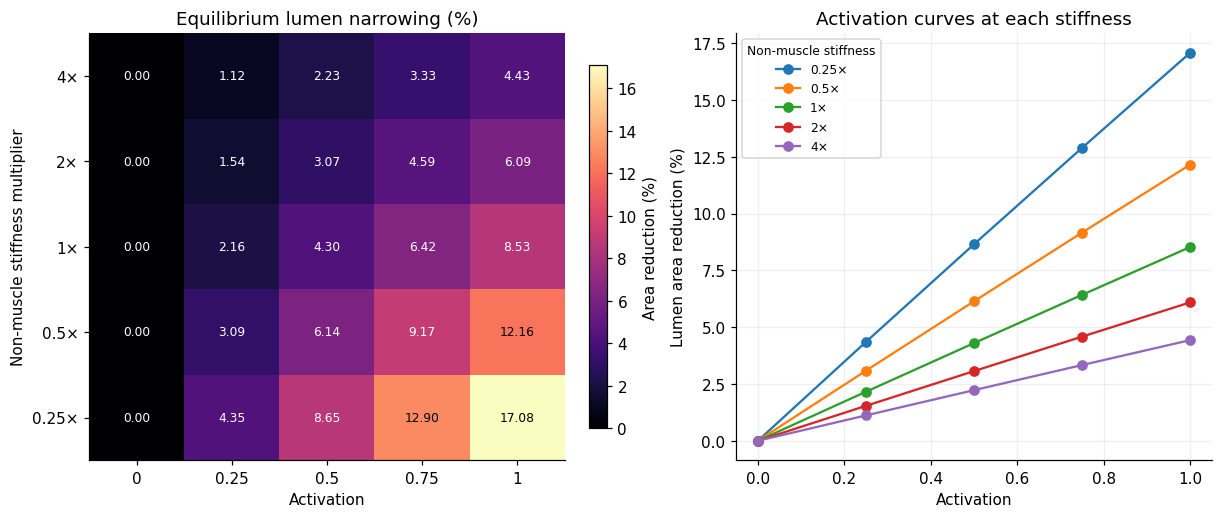

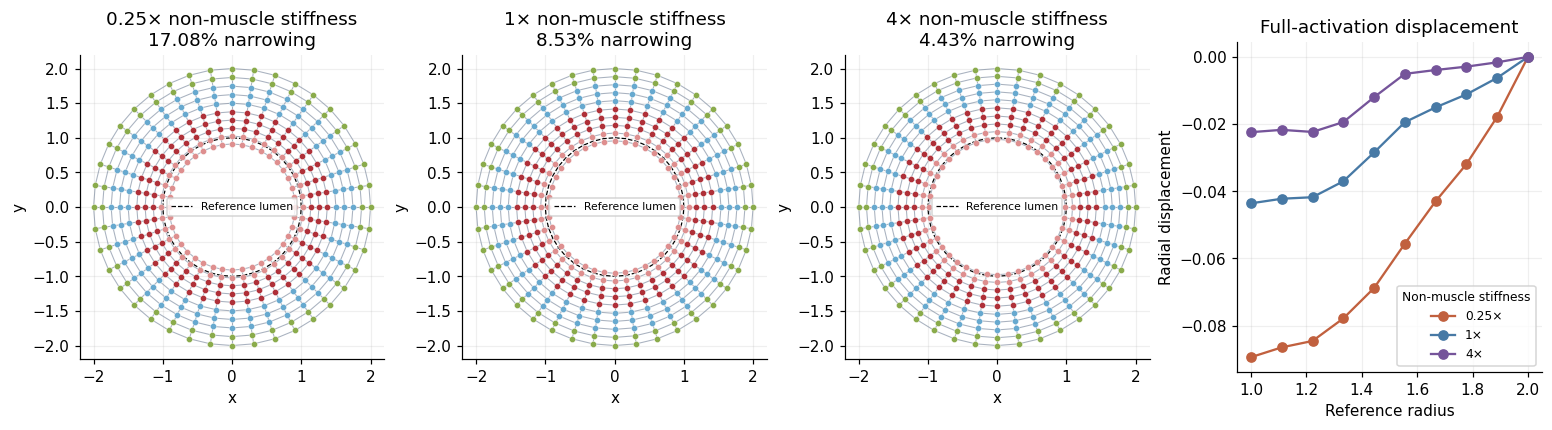

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("#dddddd")
maximum_narrowing = float(np.nanmax(sweep_grid)) if np.isfinite(sweep_grid).any() else 1.0
heatmap = axes[0].imshow(np.ma.masked_invalid(sweep_grid), origin="lower", aspect="auto",
                         cmap=cmap, vmin=0, vmax=max(maximum_narrowing, 1e-12))
axes[0].set(xticks=np.arange(len(sweep_activations)), xticklabels=[f"{a:g}" for a in sweep_activations],
            yticks=np.arange(len(stiffness_multipliers)), yticklabels=[f"{s:g}×" for s in stiffness_multipliers],
            xlabel="Activation", ylabel="Non-muscle stiffness multiplier", title="Equilibrium lumen narrowing (%)")
axes[0].grid(False)
for row, multiplier in enumerate(stiffness_multipliers):
    for column, activation in enumerate(sweep_activations):
        value = sweep_grid[row, column]
        text = f"{value:.2f}" if np.isfinite(value) else sweep_by_parameter[(float(multiplier), float(activation))]["status"].replace("_", "\n")
        color = "white" if np.isfinite(value) and value < maximum_narrowing * 0.65 else "black"
        axes[0].text(column, row, text, ha="center", va="center", color=color, fontsize=8)
fig.colorbar(heatmap, ax=axes[0], label="Area reduction (%)", shrink=0.85)
for row, multiplier in enumerate(stiffness_multipliers):
    axes[1].plot(sweep_activations, sweep_grid[row], "o-", label=f"{multiplier:g}×")
axes[1].set(xlabel="Activation", ylabel="Lumen area reduction (%)", title="Activation curves at each stiffness")
axes[1].legend(title="Non-muscle stiffness", fontsize=8, title_fontsize=8)
plt.show()

representative_multipliers = [0.25, 1.0, 4.0]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained")
comparison_colors = ["#c1603e", "#4779a5", "#75549a"]
for ax, multiplier, color in zip(axes[:3], representative_multipliers, comparison_colors):
    record = sweep_by_parameter[(multiplier, 1.0)]
    ax.set(aspect="equal", xlim=(-2.15, 2.15), ylim=(-2.15, 2.15), xlabel="x", ylabel="y")
    if record["status"] != "equilibrium":
        ax.set_title(f"{multiplier:g}×: {record['status']}")
        ax.text(0, 0, "No valid equilibrium", ha="center")
        continue
    positions = sweep_positions[(multiplier, 1.0)]
    mesh.plot(positions=positions, show_diagonal=False, ax=ax, legend=False,
              title=f"{multiplier:g}× non-muscle stiffness\n{record['equilibrium_constriction_percent']:.2f}% narrowing")
    ax.plot(*initial_lumen.T, color="black", ls="--", lw=0.8, label="Reference lumen")
    ax.legend(fontsize=7, loc="center")
    axes[3].plot(reference_radii, record["mean_radial_displacement_by_ring"], "o-", color=color, label=f"{multiplier:g}×")
axes[3].set(xlabel="Reference radius", ylabel="Radial displacement", title="Full-activation displacement")
axes[3].legend(title="Non-muscle stiffness", fontsize=8, title_fontsize=8)
plt.show()

### Save the results

Write a compact JSON report beside the notebook in `results/phase2_sweep.json`.
It contains the geometry, parameter grid, solver settings, all case summaries
and radial displacement profiles, and independent-check errors. Diagnostic
last-iterate values are distinct from equilibrium constriction, which is `null`
for rejected cases. Full trajectories remain a transient calculation; they are
not included in this report. Run from the repository root or the `backend` directory.

In [17]:
import json
import sys
from pathlib import Path

results_directory = Path("backend/results") if Path("backend/sim.ipynb").is_file() else Path("results")
results_directory.mkdir(parents=True, exist_ok=True)
results_path = results_directory / "phase2_sweep.json"
sweep_report = {
    "schema_version": 1, "units": "dimensionless",
    "geometry": {"inner_radius": mesh.r_inner, "outer_radius": mesh.r_outer,
                 "radial_rings": mesh.n_radial, "circumferential_sectors": mesh.n_circum,
                 "outer_boundary": "fixed", "reference_ring_radii": reference_radii.tolist()},
    "parameters": {"base_layer_stiffness": sweep_base_profile, "scaled_layers": list(scaled_layers),
                   "stiffness_multipliers": stiffness_multipliers.tolist(), "activations": sweep_activations.tolist(),
                   "maximum_tension": maximum_tension, "diagonal_ratio": 0.5, "damping": 1.0,
                   "external_load": 0.0, "interface_rule": "harmonic mean"},
    "solver": {"method": "overdamped Euler with energy backtracking", "force_tolerance": sweep_force_tol,
               "maximum_steps": sweep_step_limit, "save_every": sweep_save_every,
               "fresh_reference_start": True},
    "geometry_checks": {"endpoint": "positive convex cells, no collapsed springs, fixed outer boundary, no non-adjacent wall-edge intersections",
                        "saved_frames": "positive convex cells and fixed outer boundary",
                        "minimum_corner_area_ratio": 1e-8,
                        "between_saved_frames": "not certified"},
    "software": {"python": sys.version.split()[0], "numpy": np.__version__},
    "cases": sweep_records, "independent_half_step_checks": independent_checks,
}
results_path.write_text(json.dumps(sweep_report, indent=2, allow_nan=False) + "\n")
assert len(json.loads(results_path.read_text())["cases"]) == len(sweep_records)
print(f"Saved {len(sweep_records)} cases to {results_path}")
print(f"Equilibrium cases: {valid_count}; flagged cases: {len(sweep_records) - valid_count}")
if valid_count:
    print(f"Accepted narrowing range: {np.nanmin(sweep_grid):.3f}% to {np.nanmax(sweep_grid):.3f}%")
print("Phase 2 checks complete; inspect case statuses before interpreting a modified grid.")

Saved 25 cases to results/phase2_sweep.json
Equilibrium cases: 25; flagged cases: 0
Accepted narrowing range: 0.000% to 17.079%
Phase 2 checks complete; inspect case statuses before interpreting a modified grid.


These comparisons measure the response to imposed muscle tension while changing
selected passive wall stiffnesses. They do not imply that cells sense stiffness
or change their force in response. The observed relationships apply to this
grid, material profile, and outer constraint; they are not imposed as universal
monotonicity assertions. Phase 3 below examines the scaling limitation of these springs, introduces an
explicit continuum reference, and revisits this grid. Its numerical predictions
are reported separately because the constitutive assumptions change.

## 11. Phase 3 — mesh scaling and resolution

**A model change is needed for this convergence study.** The original network
specifies coefficients per spring. Refining it changes spring lengths, the
number of active rings, and, under separate radial/angular refinement, diagonal
directions. Simple geometric stiffness factors do not preserve its complete
material response. The results in sections 1–10 remain the legacy spring model.

For example, in a rectangular cell of sides $h_r,h_\theta$, assigning a diagonal
coefficient $k_d=C A/L_d^2$ makes its energy proportional to cell area $A$.
Nevertheless, under a small pure radial strain $\epsilon_{rr}$, the two diagonal
springs contribute

$$
\frac{U_d}{A}=C\epsilon_{rr}^2
\frac{h_r^4}{(h_r^2+h_\theta^2)^2}.
$$

This contribution changes with aspect ratio. Rescaling spring magnitudes alone
does not fix the orientation dependence of that construction.

The new reference model integrates a specified material energy over annular
quadrilateral elements. It reuses the geometry and tissue names, but its layer
parameters are **dimensionless elastic moduli**, not converted spring constants.
It also changes the passive constitutive law. Its mesh convergence therefore
does not establish mesh independence of the legacy spring results.

### Energy and discretization rules

Use a compressible neo-Hookean material in plane strain, with in-plane
$F=\partial\mathbf{x}/\partial\mathbf{X}$ and $J=\det F>0$:

$$
W=\frac{\mu}{2}(\mathrm{tr}(F^TF)-2)-\mu\ln J
+\frac{\lambda}{2}(\ln J)^2,
\quad \mu=\frac{E}{2(1+\nu)},\quad
\lambda=\frac{E\nu}{(1+\nu)(1-2\nu)}.
$$

This is the plane-strain restriction of the energy in the
[FEniCS hyperelasticity demo](https://docs.fenicsproject.org/dolfinx/main/cpp/demos/demo_hyperelasticity.html).
The out-of-plane stretch is one, explaining the in-plane constant 2. Choose
$\nu=0.25$ and layer moduli $(25,50,150,75)$ as an illustrative material set.
These numbers are not a fit or an equivalence to the old spring coefficients.

Use continuous bilinear quadrilaterals with two-by-two Gauss integration;
[DefElement lists the bilinear basis](https://defelement.org/elements/examples/quadrilateral-lagrange-lobatto-1.html).
Each quadrature contribution is $A_q W(F_q)$. Shape-function gradients supply
the length dependence of the nodal stiffness. For an uncoupled axial mode this
gives the familiar $k\sim E A/L^2$ scaling, while shear and normal coupling now
come from the same material law. No independent diagonal springs are added.

Layer interfaces are fixed at radii 1.2, 1.5, and 1.8. The study uses radial
interval counts divisible by 10 so each interface is a ring. Each element has
one material; shared nodes enforce continuity without averaging material values
across an interface. Report radial **intervals** explicitly: 20 intervals means
21 node rings, unlike the legacy 10-ring mesh.

Active muscle work is integrated as
$W_a=a\sigma_{\max}(|F\mathbf{t}_0|-1)$ within $1.2<R<1.5$, with the reference
circumferential direction $\mathbf{t}_0$ evaluated at quadrature points. The
coefficient $\sigma_{\max}=20$ is constant as the mesh changes. Its radial
integral is $20(0.3)=6$, matching the old three active rings × tension 2;
this is only a resultant normalization, not a match of the full material model.
An equivalent hoop-fiber discretization would assign tension in proportion to
the represented radial thickness, rather than a constant per ring.

Reference-radial dead tractions, when used, are multiplied by tributary boundary
length. Body-force densities would be multiplied by tributary area. The mesh
study applies neither external load. These integrations prevent refinement from
adding force simply by adding nodes.

`continuum.py` solves a static equilibrium using Newton steps and energy
backtracking. Because geometry, material, and activation are uniform around each
ring, it follows the rotationally symmetric branch using one radius per ring.
Every result is checked against **all two-dimensional free-node forces divided
by their reference tributary areas**, with tolerance $10^{-7}$. This avoids
making convergence easier merely by shrinking nodal forces with refinement.
Ordered positive radii prevent wall crossings on this branch. Positive element
Jacobians are required throughout the solve. This study does not assess buckling
or stability against nonsymmetric perturbations, and has no physical time axis.

In [18]:
import io
import unittest

if Path("backend/continuum.py").is_file():
    from backend.continuum import ContinuumAirway
    from backend.test_continuum import ContinuumTests
else:
    from continuum import ContinuumAirway
    from test_continuum import ContinuumTests

test_output = io.StringIO()
verification = unittest.TextTestRunner(stream=test_output).run(unittest.defaultTestLoader.loadTestsFromTestCase(ContinuumTests))
print(test_output.getvalue())
assert verification.wasSuccessful()

continuum_moduli = {"mucosa": 25.0, "muscle": 50.0, "cartilage": 150.0, "adventitia": 75.0}
continuum_stress = 20.0
continuum_nu = 0.25
continuum_force_tol = 1e-7
# Criteria are fixed before running the study; percentage points are absolute.
mesh_tolerances = {"narrowing_percentage_points": 0.05,
                   "relative_lumen_area": 0.001,
                   "maximum_radial_displacement": 0.0002}
profile_sample_radii = np.linspace(1, 2, 501)
reference_resolution = (80, 160)  # Radial intervals, angular sectors.
working_resolution = (20, 80)

........
----------------------------------------------------------------------
Ran 8 tests in 0.075s

OK



### Refinement study and acceptance criteria

Compare four resolutions per refinement path: radial intervals 10, 20, 40, 80
at 160 sectors; sectors 20, 40, 80, 160 at 80 radial intervals; and joint
refinement (10,20), (20,40), (40,80), (80,160). The shared finest mesh is a
numerical reference, not an exact solution.

Require differences from that reference of at most **0.05 percentage points**
in narrowing, **0.1%** in absolute lumen area, and **0.0002** in maximum radial
displacement. Compare displacement profiles by linear interpolation onto 501
common reference radii, including the tissue boundaries. Absolute area is checked
separately because each polygon's starting area changes with angular resolution.

Test a working candidate of **20 radial intervals × 80 sectors**. Tighten its
force-density tolerance by tenfold to separate incomplete mechanical relaxation
from spatial discretization error. Finally, check that the working candidate
meets the same mesh criteria at every point of the phase 2 parameter grid.

In [19]:
def solve_continuum(resolution, multiplier=1.0, activation=1.0, tolerance=continuum_force_tol):
    moduli = {key: value * (1 if key == "muscle" else multiplier) for key, value in continuum_moduli.items()}
    model = ContinuumAirway(*resolution, moduli=moduli, poisson_ratio=continuum_nu,
                           active_stress=continuum_stress, activation=activation)
    result = model.solve(force_density_tol=tolerance)
    assert result["converged"], (resolution, multiplier, activation, result["residual_density"])
    np.testing.assert_array_equal(result["positions"][model.fixed], model.reference[model.fixed])
    assert np.diff(result["radii"]).min() > 0 and result["radii"][0] > 0
    assert result["minimum_jacobian"] > 0
    assert np.max(np.diff([entry["potential"] for entry in result["history"]]), initial=0) <= 1e-9
    return model, result


def mesh_errors(result, reference_result):
    profile = np.interp(profile_sample_radii, result["reference_radii"], result["radii"] - result["reference_radii"])
    reference_profile = np.interp(profile_sample_radii, reference_result["reference_radii"],
                                  reference_result["radii"] - reference_result["reference_radii"])
    errors = {
        "narrowing_percentage_points": abs(result["narrowing_percent"] - reference_result["narrowing_percent"]),
        "relative_lumen_area": abs(result["lumen_area"] / reference_result["lumen_area"] - 1),
        "maximum_radial_displacement": float(np.max(np.abs(profile - reference_profile))),
    }
    return {**errors, "accepted": all(errors[key] <= threshold for key, threshold in mesh_tolerances.items())}


refinement_paths = {
    "Radial refinement": [(n, 160) for n in (10, 20, 40, 80)],
    "Angular refinement": [(80, n) for n in (20, 40, 80, 160)],
    "Joint refinement": [(10, 20), (20, 40), (40, 80), (80, 160)],
}
resolutions = sorted({item for path in refinement_paths.values() for item in path} | {working_resolution})
mesh_runs = {}
for resolution in resolutions:
    _, result = solve_continuum(resolution)
    mesh_runs[resolution] = result
    print(f"{resolution[0]:2d} intervals × {resolution[1]:3d} sectors: "
          f"{result['narrowing_percent']:.6f}% narrowing; force density {result['residual_density']:.2e}")

finest = mesh_runs[reference_resolution]
mesh_comparisons = {resolution: mesh_errors(result, finest) for resolution, result in mesh_runs.items()}
for name, path in refinement_paths.items():
    for metric in mesh_tolerances:
        values = np.array([mesh_comparisons[resolution][metric] for resolution in path])
        assert np.all(np.diff(values) <= 1e-10), (name, metric, values)
assert mesh_comparisons[working_resolution]["accepted"]

_, tighter = solve_continuum(working_resolution, tolerance=continuum_force_tol / 10)
solver_tolerance_errors = mesh_errors(tighter, mesh_runs[working_resolution])
assert solver_tolerance_errors["narrowing_percentage_points"] < mesh_tolerances["narrowing_percentage_points"] / 100
assert solver_tolerance_errors["maximum_radial_displacement"] < mesh_tolerances["maximum_radial_displacement"] / 100
print("Working-mesh errors:", mesh_comparisons[working_resolution])
print("Effect of tenfold tighter force tolerance:", solver_tolerance_errors)

10 intervals ×  20 sectors: 5.315284% narrowing; force density 9.66e-09


10 intervals × 160 sectors: 5.357592% narrowing; force density 1.08e-08


20 intervals ×  40 sectors: 5.342545% narrowing; force density 3.90e-08


20 intervals ×  80 sectors: 5.350553% narrowing; force density 3.98e-08


20 intervals × 160 sectors: 5.352551% narrowing; force density 4.00e-08


40 intervals ×  80 sectors: 5.349291% narrowing; force density 1.86e-10


40 intervals × 160 sectors: 5.351289% narrowing; force density 2.20e-10
80 intervals ×  20 sectors: 5.308697% narrowing; force density 7.00e-10


80 intervals ×  40 sectors: 5.340970% narrowing; force density 7.81e-10


80 intervals ×  80 sectors: 5.348976% narrowing; force density 9.56e-10


80 intervals × 160 sectors: 5.350974% narrowing; force density 1.01e-09
Working-mesh errors: {'narrowing_percentage_points': 0.00042113490277273513, 'relative_lumen_area': 0.0007665177523857869, 'maximum_radial_displacement': 7.660384009301399e-05, 'accepted': True}
Effect of tenfold tighter force tolerance: {'narrowing_percentage_points': 5.011990822367807e-10, 'relative_lumen_area': 5.295430760554609e-12, 'maximum_radial_displacement': 2.5760504840377507e-12, 'accepted': True}


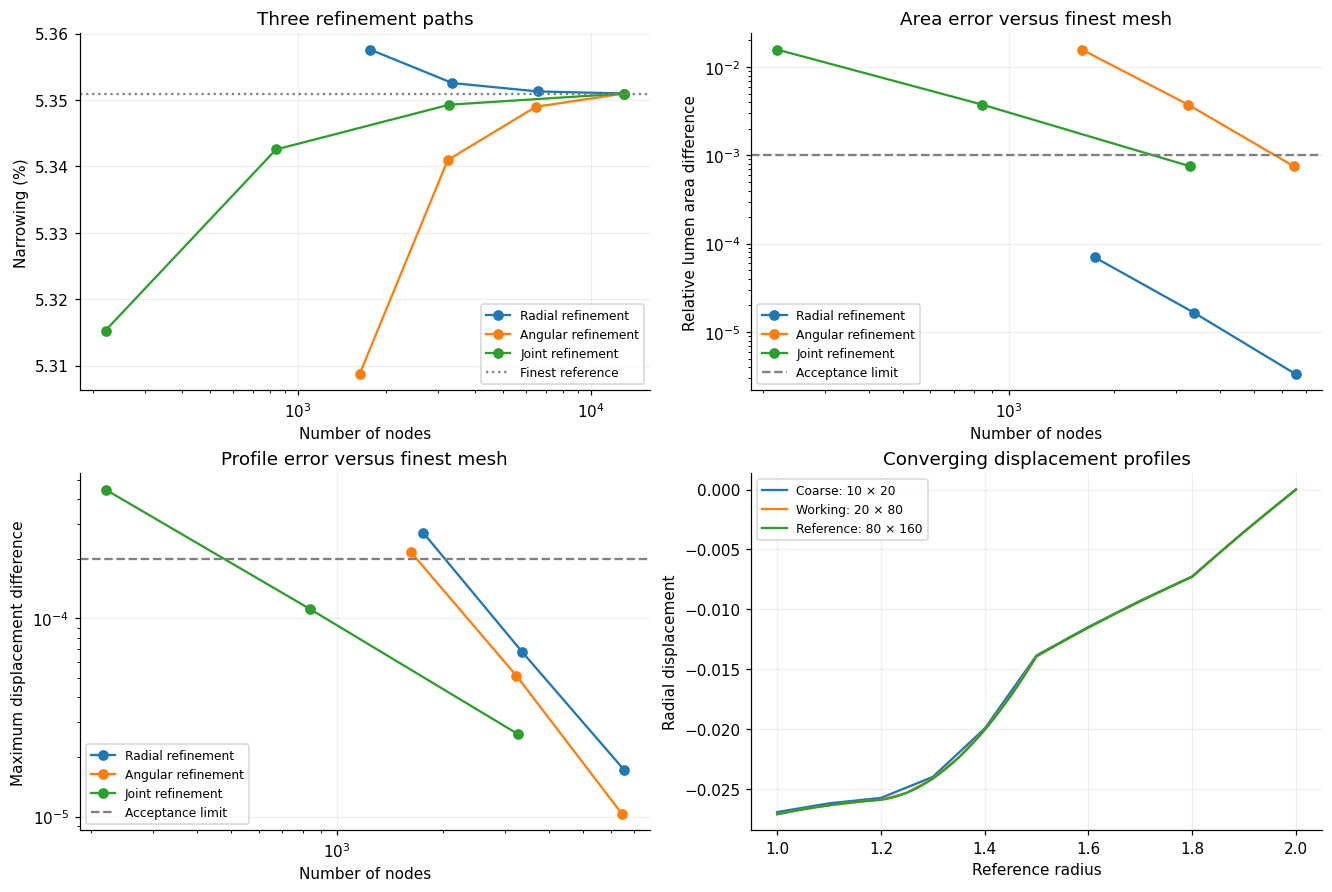

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for name, path in refinement_paths.items():
    nodes = [(nr + 1) * nc for nr, nc in path]
    axes[0, 0].plot(nodes, [mesh_runs[key]["narrowing_percent"] for key in path], "o-", label=name)
    # The final reference point has zero comparison error; omit it on log axes.
    axes[0, 1].loglog(nodes[:-1], [mesh_comparisons[key]["relative_lumen_area"] for key in path[:-1]], "o-", label=name)
    axes[1, 0].loglog(nodes[:-1], [mesh_comparisons[key]["maximum_radial_displacement"] for key in path[:-1]], "o-", label=name)
axes[0, 0].axhline(finest["narrowing_percent"], color="gray", ls=":", label="Finest reference")
axes[0, 0].set(xscale="log", xlabel="Number of nodes", ylabel="Narrowing (%)", title="Three refinement paths")
axes[0, 1].axhline(mesh_tolerances["relative_lumen_area"], color="gray", ls="--", label="Acceptance limit")
axes[0, 1].set(xlabel="Number of nodes", ylabel="Relative lumen area difference", title="Area error versus finest mesh")
axes[1, 0].axhline(mesh_tolerances["maximum_radial_displacement"], color="gray", ls="--", label="Acceptance limit")
axes[1, 0].set(xlabel="Number of nodes", ylabel="Maximum displacement difference", title="Profile error versus finest mesh")
for resolution, label in [((10, 20), "Coarse: 10 × 20"), (working_resolution, "Working: 20 × 80"),
                           (reference_resolution, "Reference: 80 × 160")]:
    result = mesh_runs[resolution]
    axes[1, 1].plot(result["reference_radii"], result["radii"] - result["reference_radii"], label=label)
axes[1, 1].set(xlabel="Reference radius", ylabel="Radial displacement", title="Converging displacement profiles")
for ax in axes.flat:
    ax.legend(fontsize=8)
plt.show()

### Revisit phase 2 under the new constitutive assumptions

Repeat all 25 parameter combinations on the working and finest meshes, with
non-muscle moduli scaled together and muscle modulus fixed. Start every case
from its reference geometry. Require all three mesh-error criteria at every grid
point, and retain the old spring heatmap alongside the new continuum result.

Agreement of the **trend** between these models does not validate either model
against tissue data. Any change in the numerical narrowing values includes the
new passive law, interface treatment, and active-work discretization, so it must
not be described as a pure mesh correction to the legacy model.

In [21]:
continuum_sweep = []
continuum_grid = np.zeros_like(sweep_grid)
for row, multiplier in enumerate(stiffness_multipliers):
    for column, activation in enumerate(sweep_activations):
        _, working_result = solve_continuum(working_resolution, multiplier, activation)
        _, reference_result = solve_continuum(reference_resolution, multiplier, activation)
        errors = mesh_errors(working_result, reference_result)
        assert errors["accepted"], (multiplier, activation, errors)
        if activation == 0:
            assert working_result["iterations"] == reference_result["iterations"] == 0
            assert abs(working_result["narrowing_percent"]) < 1e-12
        continuum_grid[row, column] = working_result["narrowing_percent"]
        continuum_sweep.append({
            "stiffness_multiplier": float(multiplier), "activation": float(activation),
            "working_narrowing_percent": working_result["narrowing_percent"],
            "reference_narrowing_percent": reference_result["narrowing_percent"],
            "legacy_spring_narrowing_percent": sweep_by_parameter[(float(multiplier), float(activation))]["equilibrium_constriction_percent"],
            "working_residual_density": working_result["residual_density"],
            "reference_residual_density": reference_result["residual_density"],
            "working_minimum_jacobian": working_result["minimum_jacobian"],
            "reference_minimum_jacobian": reference_result["minimum_jacobian"],
            "working_radial_displacement": (working_result["radii"] - working_result["reference_radii"]).tolist(),
            "mesh_errors": errors,
        })
    print(f"Multiplier {multiplier:g}: all activations pass; continuum full-activation narrowing "
          f"{continuum_grid[row, -1]:.6f}%", flush=True)
worst_grid_errors = {key: max(case["mesh_errors"][key] for case in continuum_sweep) for key in mesh_tolerances}
print("Worst working-mesh errors over the entire grid:", worst_grid_errors)
print("Working resolution accepted: 20 radial intervals (21 rings) × 80 sectors.")

Multiplier 0.25: all activations pass; continuum full-activation narrowing 13.865466%


Multiplier 0.5: all activations pass; continuum full-activation narrowing 8.317316%


Multiplier 1: all activations pass; continuum full-activation narrowing 5.350553%


Multiplier 2: all activations pass; continuum full-activation narrowing 3.795195%


Multiplier 4: all activations pass; continuum full-activation narrowing 2.944526%


Worst working-mesh errors over the entire grid: {'narrowing_percentage_points': 0.004512537398293048, 'relative_lumen_area': 0.000776318365277695, 'maximum_radial_displacement': 8.17688994510235e-05}
Working resolution accepted: 20 radial intervals (21 rings) × 80 sectors.


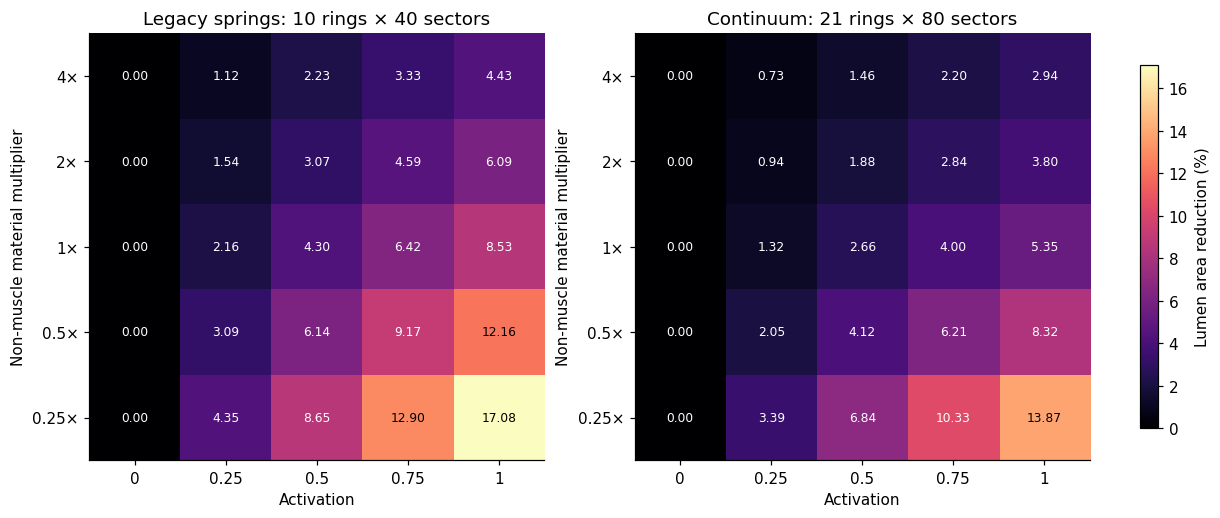

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
common_max = max(float(np.nanmax(sweep_grid)), float(np.max(continuum_grid)))
for ax, values, title in zip(axes, [sweep_grid, continuum_grid],
                             ["Legacy springs: 10 rings × 40 sectors", "Continuum: 21 rings × 80 sectors"]):
    heat = ax.imshow(np.ma.masked_invalid(values), origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=common_max)
    ax.set(xticks=np.arange(len(sweep_activations)), xticklabels=[f"{a:g}" for a in sweep_activations],
           yticks=np.arange(len(stiffness_multipliers)), yticklabels=[f"{s:g}×" for s in stiffness_multipliers],
           xlabel="Activation", ylabel="Non-muscle material multiplier", title=title)
    ax.grid(False)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            ax.text(column, row, f"{value:.2f}" if np.isfinite(value) else "flagged", ha="center", va="center",
                    fontsize=8, color="white" if value < 0.65 * common_max else "black")
fig.colorbar(heat, ax=axes, label="Lumen area reduction (%)", shrink=0.85)
plt.show()

### Save the convergence evidence

The report below records the material law, physical layer boundaries, active-work
normalization, load integration, solver tolerance, every refinement case, the
acceptance thresholds, the tolerance-tightening result, and all 25 revisited
parameter combinations. It also records the scope of the verification: the
rotationally symmetric continuum branch. The original spring report is preserved.

The accepted mesh is a working choice for this parameter grid and these output
tolerances. Different geometry, material contrast, or asymmetric loading requires
a new study. Phase 4 can use this continuum branch as a mechanical reference,
but coupling kinetic time to mechanics will need a separate modelling choice.

In [23]:
phase3_report = {
    "schema_version": 1, "units": "dimensionless", "legacy_spring_report": "phase2_sweep.json",
    "model": {"passive_law": "compressible neo-Hookean plane strain", "element": "bilinear Q1 quadrilateral",
              "quadrature": "2 by 2 Gauss", "moduli": continuum_moduli, "poisson_ratio": continuum_nu,
              "active_potential_density": "activation * active_stress * (norm(F @ reference_tangent) - 1)",
              "maximum_active_stress": continuum_stress, "muscle_radial_thickness": 0.3,
              "material_interfaces": [1.2, 1.5, 1.8], "inner_radius": 1.0, "outer_radius": 2.0,
              "outer_boundary": "fixed", "material_interface_rule": "continuous displacement across shared nodes",
              "external_load": 0, "load_scaling": "boundary traction times tributary length; body force times tributary area",
              "spring_parameter_equivalence": False},
    "solver": {"method": "Newton with admissibility and energy backtracking", "branch": "rotationally symmetric",
               "residual_check": "all 2D free-node force norms divided by reference tributary area",
               "force_density_tolerance": continuum_force_tol, "nonsymmetric_stability_tested": False},
    "acceptance_tolerances": mesh_tolerances,
    "reference_resolution": {"radial_intervals": reference_resolution[0], "sectors": reference_resolution[1]},
    "working_resolution": {"radial_intervals": working_resolution[0], "node_rings": working_resolution[0] + 1,
                           "sectors": working_resolution[1]},
    "refinement_paths": refinement_paths,
    "refinement_cases": [
        {"radial_intervals": resolution[0], "sectors": resolution[1],
         "converged": result["converged"], "iterations": result["iterations"],
         "narrowing_percent": result["narrowing_percent"], "lumen_area": result["lumen_area"],
         "residual_density": result["residual_density"], "minimum_jacobian": result["minimum_jacobian"],
         "reference_radii": result["reference_radii"].tolist(), "deformed_radii": result["radii"].tolist(),
         "errors_to_finest": mesh_comparisons[resolution]} for resolution, result in mesh_runs.items()],
    "tightened_solver_tolerance": continuum_force_tol / 10,
    "solver_tolerance_errors": solver_tolerance_errors,
    "revisited_sweep": continuum_sweep, "worst_grid_mesh_errors": worst_grid_errors,
    "verification_tests_passed": verification.testsRun,
    "sources": ["https://docs.fenicsproject.org/dolfinx/main/cpp/demos/demo_hyperelasticity.html",
                "https://defelement.org/elements/examples/quadrilateral-lagrange-lobatto-1.html"],
}
phase3_path = results_directory / "phase3_mesh_convergence.json"
phase3_path.write_text(json.dumps(phase3_report, indent=2, allow_nan=False) + "\n")
assert len(json.loads(phase3_path.read_text())["revisited_sweep"]) == 25
print(f"Saved convergence evidence to {phase3_path}")
print("Phase 3: PASS for the specified continuum model, symmetric branch, grid, and tolerances.")

Saved convergence evidence to results/phase3_mesh_convergence.json
Phase 3: PASS for the specified continuum model, symmetric branch, grid, and tolerances.


## 12. Time-dependent cross-bridge kinetics (phase 4)

Use the four-state scheme in Hai and Murphy, *Regulation of shortening velocity
by cross-bridge phosphorylation in smooth muscle*, **1988**, 255:C86–C94
([paper and DOI](https://doi.org/10.1152/ajpcell.1988.255.1.C86)). The local
`hai1988.pdf` is this July paper. Its pp. C86–C87 and Fig. 1A restate the kinetic
scheme from their earlier [January paper](https://doi.org/10.1152/ajpcell.1988.254.1.C99).
We implement that four-state scheme, not the July paper's later Huxley
force–velocity extension.

| Fraction | Attachment | Phosphorylation |
|---|---|---|
| $M$ | Detached | Dephosphorylated |
| $M_p$ | Detached | Phosphorylated |
| $AM_p$ | Attached | Phosphorylated |
| $AM$ | Attached (latch) | Dephosphorylated |

All fractions are dimensionless and sum to one. The reference rate constants
below are in $\mathrm{s}^{-1}$; Hai and Murphy obtained them from fits to
**electrically stimulated swine carotid media**, not airway tissue (p. C86).

| Transition | Rate | Value / source |
|---|---|---|
| $M\to M_p$, $AM\to AM_p$ | $k_1=k_6=k(t)$ | Prescribed kinase input; protocol below is illustrative |
| $M_p\to M$, $AM_p\to AM$ | $k_2=k_5$ | 0.5, paper p. C86 |
| $M_p\to AM_p$ | $k_3$ | 0.4, paper p. C86 |
| $AM_p\to M_p$ | $k_4$ | 0.1, paper p. C86 |
| $AM\to M$ | $k_7$ | 0.01, paper p. C86 |

Equality of the free and attached phosphorylation/dephosphorylation rates is a
model assumption (p. C87). We prescribe $k(t)$ directly; no calcium concentration,
agonist dose, or calcium-to-kinase relationship is inferred.

### Equations, tension, and the two clocks

The seven transitions give

$$
\begin{aligned}
\dot M&=-k_1M+k_2M_p+k_7AM,\\
\dot M_p&=k_1M-(k_2+k_3)M_p+k_4AM_p,\\
\dot{AM}_p&=k_3M_p-(k_4+k_5)AM_p+k_6AM,\\
\dot{AM}&=k_5AM_p-(k_6+k_7)AM.
\end{aligned}
$$

Adding these equations gives zero. Nonnegative transition rates preserve
nonnegative populations. `hai_murphy.py` propagates $y(t+h)=\exp(Qh)y(t)$ on each
constant-rate interval and splits at **every** input switch, even if the output
grid misses it. This has no finite-step truncation error on those intervals;
roundoff and output sampling still need checks. No population clipping or
renormalization is used to hide errors.

Phosphorylation is $p=M_p+AM_p$, while attachment is $a=AM_p+AM$.
Following the paper's equal load-bearing assumption (p. C87), both attached
states contribute equally. For the wall, choose the additional constitutive rule

$$
T(t)=\sigma_{\max}a(t),\qquad
W_a(F,t)=T(t)(|F\mathbf t_0|-1),\qquad \sigma_{\max}=20.
$$

Here $T$ is the **dimensionless nominal active tension density** in the muscle
layer, not force in newtons or a calibrated Cauchy stress. The scale 20 and wall
parameters come from section 11; attachment is not renormalized to its peak or
steady-state value. Thus $a=1$ recovers that section's full-activation load.

At each output time, solve a fresh equilibrium on the accepted 20-interval ×
80-sector mesh. This is a **one-way quasistatic approximation**: the wall is
assumed to equilibrate rapidly compared with cross-bridge kinetics. Newton
iterations have no duration in seconds. There is no viscous wall delay, strain
feedback to rates, or force–velocity relation; the rate fit was isometric, so
applying it while the wall shortens is an explicit simplification. Each snapshot
must pass the full force-density, Jacobian, radius-ordering, and fixed-boundary
checks before it can appear in the time course.

In [24]:
from dataclasses import asdict
import scipy

if Path("backend/hai_murphy.py").is_file():
    from backend.hai_murphy import HaiMurphyRates, ActivationProtocol, STATE_NAMES, simulate, quasistatic_response
    from backend.test_hai_murphy import HaiMurphyTests
else:
    from hai_murphy import HaiMurphyRates, ActivationProtocol, STATE_NAMES, simulate, quasistatic_response
    from test_hai_murphy import HaiMurphyTests

kinetic_test_output = io.StringIO()
kinetic_verification = unittest.TextTestRunner(stream=kinetic_test_output).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(HaiMurphyTests))
print(kinetic_test_output.getvalue())
assert kinetic_verification.wasSuccessful()
hm_rates = HaiMurphyRates()
print("Fixed kinetic rates (1/s):", asdict(hm_rates))

.........
----------------------------------------------------------------------
Ran 9 tests in 0.112s

OK

Fixed kinetic rates (1/s): {'k2': 0.5, 'k3': 0.4, 'k4': 0.1, 'k5': 0.5, 'k7': 0.01}


### Comparison with the published model

Compare stationary numerical populations with **Eqs. 3–4 and Fig. 2A on p. C87**.
These are analytic model references, not new experimental measurements. With
$D=k_4k_6+k_4k_7+k_5k_7$, the published apparent rates are

$$
f=\frac{k_1k_3D}{(k_1+k_2)D+k_3k_5k_7},\qquad
 g=\frac{D}{k_5+k_6+k_7}.
$$

Independently obtain them from the numerical stationary populations as
$f=k_3M_p/(M+M_p)$ and $g=(k_4AM_p+k_7AM)/(AM_p+AM)$.
Matching these curves checks the kinetic scheme; it does not reproduce all of
the paper's force–velocity experiments or validate the airway wall. Unit tests
also compare transient solutions with a separately written adaptive ODE solver
and isolated transitions with their exact exponential solutions.

Maximum discrepancy from published Eqs. 3–4: 5.551e-17 1/s


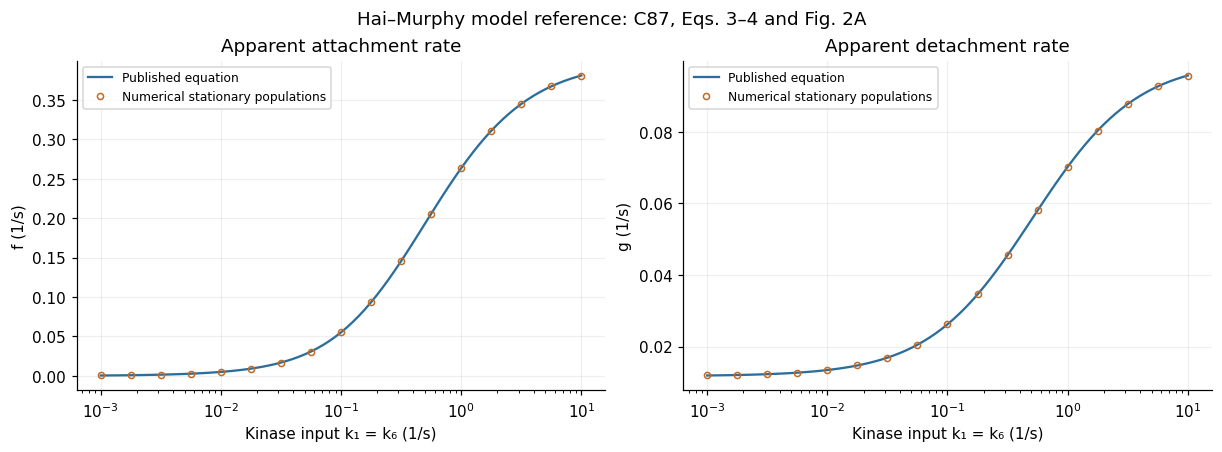

In [25]:
reference_kinase = np.logspace(-3, 1, 81)
stationary = np.array([hm_rates.steady_state(k) for k in reference_kinase])
stationary_attached = stationary[:, 2] + stationary[:, 3]
f_numerical = hm_rates.k3 * stationary[:, 1] / stationary[:, :2].sum(axis=1)
g_numerical = (hm_rates.k4 * stationary[:, 2] + hm_rates.k7 * stationary[:, 3]) / stationary_attached
D = hm_rates.k4 * reference_kinase + hm_rates.k4 * hm_rates.k7 + hm_rates.k5 * hm_rates.k7
f_reference = reference_kinase * hm_rates.k3 * D / (
    (reference_kinase + hm_rates.k2) * D + hm_rates.k3 * hm_rates.k5 * hm_rates.k7)
g_reference = D / (hm_rates.k5 + reference_kinase + hm_rates.k7)
published_reference_error = float(max(np.max(abs(f_numerical - f_reference)),
                                      np.max(abs(g_numerical - g_reference))))
assert published_reference_error < 1e-12
np.testing.assert_allclose(stationary_attached, f_reference / (f_reference + g_reference), atol=1e-13)
print(f"Maximum discrepancy from published Eqs. 3–4: {published_reference_error:.3e} 1/s")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, reference, numerical, symbol, title in zip(
        axes, [f_reference, g_reference], [f_numerical, g_numerical],
        ["f", "g"], ["Apparent attachment rate", "Apparent detachment rate"]):
    ax.semilogx(reference_kinase, reference, color="#2c6e9b", label="Published equation")
    ax.semilogx(reference_kinase[::5], numerical[::5], "o", ms=4, mfc="none",
                color="#c36a24", label="Numerical stationary populations")
    ax.set(xlabel="Kinase input k₁ = k₆ (1/s)", ylabel=f"{symbol} (1/s)", title=title)
    ax.legend(fontsize=8)
fig.suptitle("Hai–Murphy model reference: C87, Eqs. 3–4 and Fig. 2A")
plt.show()

### Activation, sustained input, and withdrawal

Start with $(M,M_p,AM_p,AM)=(1,0,0,0)$. The illustrative stimulus is
$k=0$ before 10 s, $0.55\ \mathrm{s}^{-1}$ from 10 to 30 s,
$0.10\ \mathrm{s}^{-1}$ from 30 to 120 s, and zero thereafter. Values are
right-continuous at switches, but populations and tension are continuous.
This protocol illustrates onset, lower sustained phosphorylation, and relaxation;
it is not a digitized experimental stimulus.

Check population conservation and nonnegativity, the zero-input resting limit,
and the closed scalar equation $\dot p=k(1-p)-0.5p$. Compare the exact propagator
with independent fourth-order Runge–Kutta integrations at steps 0.5, 0.25, 0.125, and
0.0625 s, splitting at switches. Their errors should decrease under refinement.
After withdrawal, phosphorylation decays on the 2 s timescale while the late
latch tail has the $1/k_7=100$ s timescale. These are consequences of the chosen
rates, not measured airway relaxation times.

In [26]:
protocol = ActivationProtocol((0, 10, 30, 120), (0, 0.55, 0.10, 0))
# Fine output spacing: 0.25 s through 160 s, then 1.25 s to 600 s.
# Every second point forms a coarser 0.5 / 2.5 s output grid.
kinetic_times = np.r_[np.arange(0, 160.25, .25), np.arange(161.25, 600.01, 1.25)]
kinetic_states = simulate(kinetic_times, protocol, rates=hm_rates)
coarse_times = kinetic_times[::2]
coarse_states = simulate(coarse_times, protocol, rates=hm_rates)
common_time_error = float(np.max(abs(coarse_states - kinetic_states[::2])))
mass_error = float(np.max(abs(kinetic_states.sum(axis=1) - 1)))
minimum_population = float(kinetic_states.min())
assert mass_error < 1e-12 and minimum_population >= -1e-12
assert common_time_error < 1e-12
np.testing.assert_array_equal(kinetic_states[kinetic_times <= 10],
                              np.tile([1, 0, 0, 0], ((kinetic_times <= 10).sum(), 1)))

# An independent scalar solution for total phosphorylation, interval by interval.
phosphorylation_reference = np.empty(len(kinetic_times))
p_start = 0.0
boundaries = [*protocol.switch_times, kinetic_times[-1]]
for start, end, kinase in zip(boundaries[:-1], boundaries[1:], protocol.kinase_rates):
    selected = (kinetic_times >= start) & (kinetic_times <= end)
    p_inf = kinase / (kinase + hm_rates.k2)
    phosphorylation_reference[selected] = p_inf + (p_start - p_inf) * np.exp(
        -(kinase + hm_rates.k2) * (kinetic_times[selected] - start))
    p_start = p_inf + (p_start - p_inf) * np.exp(-(kinase + hm_rates.k2) * (end - start))
phosphorylation = kinetic_states[:, 1] + kinetic_states[:, 2]
phosphorylation_error = float(np.max(abs(phosphorylation - phosphorylation_reference)))
assert phosphorylation_error < 1e-12

# Independent RK4 time discretization; scalar time steps divide the switch times.
def rk4_reference(step):
    state = np.array([1., 0, 0, 0])
    sampled = [state.copy()]
    steps_per_second = round(1 / step)
    for i in range(round(600 / step)):
        k = float(protocol.values((i + .5) * step))
        # Explicit flux equations, independent of the module's Q assembly.
        def rhs(y):
            m, mp, amp, am = y
            return np.array([-k*m + .5*mp + .01*am, k*m - .9*mp + .1*amp,
                             .4*mp - .6*amp + k*am, .5*amp - (k + .01)*am])
        a = rhs(state)
        b = rhs(state + step*a/2)
        c = rhs(state + step*b/2)
        d = rhs(state + step*c)
        state = state + step*(a + 2*b + 2*c + d)/6
        if (i + 1) % steps_per_second == 0:
            sampled.append(state.copy())
    return np.array(sampled)

rk4_steps = np.array([.5, .25, .125, .0625])
integer_reference = simulate(np.arange(601.), protocol)
rk4_errors = np.array([np.max(abs(rk4_reference(step) - integer_reference)) for step in rk4_steps])
assert np.all(rk4_errors[1:] < rk4_errors[:-1] / 8)
assert rk4_errors[-1] < 1e-6
print(f"Population sum error: {mass_error:.3e}; minimum fraction: {minimum_population:.3e}")
print(f"Exact propagation, coarser vs finer common times: {common_time_error:.3e}")
print(f"Scalar phosphorylation reference error: {phosphorylation_error:.3e}")
for step, error in zip(rk4_steps, rk4_errors):
    print(f"Independent RK4, step {step:.3f} s: maximum fraction error {error:.3e}")

Population sum error: 1.932e-14; minimum fraction: 0.000e+00
Exact propagation, coarser vs finer common times: 2.731e-14
Scalar phosphorylation reference error: 2.276e-15
Independent RK4, step 0.500 s: maximum fraction error 4.440e-04
Independent RK4, step 0.250 s: maximum fraction error 2.099e-05
Independent RK4, step 0.125 s: maximum fraction error 1.143e-06
Independent RK4, step 0.062 s: maximum fraction error 6.666e-08


### Coupled wall time course and sampling sensitivity

Compute every fine-grid wall snapshot directly; do not interpolate activation
through a fitted load–narrowing curve. Compare linear interpolation of the
coarser snapshots with the intervening direct solves, requiring less than
**0.05 percentage points** difference in narrowing. This measures the effect of
output spacing, separately from kinetic integration, Newton convergence, and
spatial mesh error. The final displayed curve uses the finer output grid.

Independently rerun selected shared samples from the coarser kinetic trajectory
and compare their radii. Also compare the peak and two relaxation snapshots with
the finest spatial mesh using the section 11 criteria. These checks validate the
implementation of the stated quasistatic approximation; they do not establish
that real airway tissue equilibrates instantaneously.

In [27]:
wall_options = {"radial_intervals": working_resolution[0], "sectors": working_resolution[1],
                "moduli": continuum_moduli, "poisson_ratio": continuum_nu,
                "tension_scale": continuum_stress, "force_density_tol": continuum_force_tol}
wall_timecourse = quasistatic_response(kinetic_states, **wall_options)
assert wall_timecourse["converged"].all()
assert np.max(wall_timecourse["residual_density"]) <= continuum_force_tol
coarse_narrowing = wall_timecourse["narrowing_percent"][::2]
interpolated_narrowing = np.interp(kinetic_times, coarse_times, coarse_narrowing)
sampling_error = float(np.max(abs(interpolated_narrowing - wall_timecourse["narrowing_percent"])))
sampling_tolerance = .05  # Absolute percentage points.
assert sampling_error < sampling_tolerance

shared_indices = np.array([np.flatnonzero(coarse_times == t)[0] for t in (0, 20, 30, 120, 220, 600)])
shared_wall = quasistatic_response(coarse_states[shared_indices], **wall_options)
shared_radius_error = float(np.max(abs(shared_wall["radii"] - wall_timecourse["radii"][2*shared_indices])))
assert shared_radius_error < 1e-10

peak_index = int(np.argmax(wall_timecourse["narrowing_percent"]))
kinetic_mesh_checks = []
for index in (peak_index, int(np.flatnonzero(kinetic_times == 120)[0]),
              int(np.flatnonzero(kinetic_times == 220)[0])):
    _, fine_snapshot = solve_continuum(reference_resolution, activation=float(wall_timecourse["attached_fraction"][index]))
    working_snapshot = {key: wall_timecourse[key][index] for key in ("narrowing_percent", "lumen_area", "radii")}
    working_snapshot["reference_radii"] = wall_timecourse["reference_radii"]
    errors = mesh_errors(working_snapshot, fine_snapshot)
    assert errors["accepted"]
    kinetic_mesh_checks.append({"time_seconds": float(kinetic_times[index]), "errors": errors})

# The late tension tail should have the latch-detachment slope.
i220 = int(np.flatnonzero(kinetic_times == 220)[0])
i320 = int(np.flatnonzero(kinetic_times == 320)[0])
late_tension_ratio = float(wall_timecourse["tension_density"][i320] / wall_timecourse["tension_density"][i220])
np.testing.assert_allclose(late_tension_ratio, np.exp(-hm_rates.k7 * 100), atol=1e-12)
print(f"Accepted {len(kinetic_times)} quasistatic wall snapshots.")
print(f"Peak narrowing: {wall_timecourse['narrowing_percent'][peak_index]:.6f}% at {kinetic_times[peak_index]:.2f} s")
print(f"Narrowing at 600 s: {wall_timecourse['narrowing_percent'][-1]:.6f}%")
print(f"Coarse-output interpolation error: {sampling_error:.6f} percentage points (limit {sampling_tolerance})")
print(f"Independent shared-sample radius difference: {shared_radius_error:.3e}")
print(f"Maximum force density: {np.max(wall_timecourse['residual_density']):.3e}")
print(f"Three kinetic snapshots pass the finest-mesh comparison; late 100 s tension ratio: {late_tension_ratio:.6f}")

Accepted 993 quasistatic wall snapshots.
Peak narrowing: 4.087249% at 30.50 s
Narrowing at 600 s: 0.029795%
Coarse-output interpolation error: 0.024663 percentage points (limit 0.05)
Independent shared-sample radius difference: 4.441e-16
Maximum force density: 9.985e-08
Three kinetic snapshots pass the finest-mesh comparison; late 100 s tension ratio: 0.367879


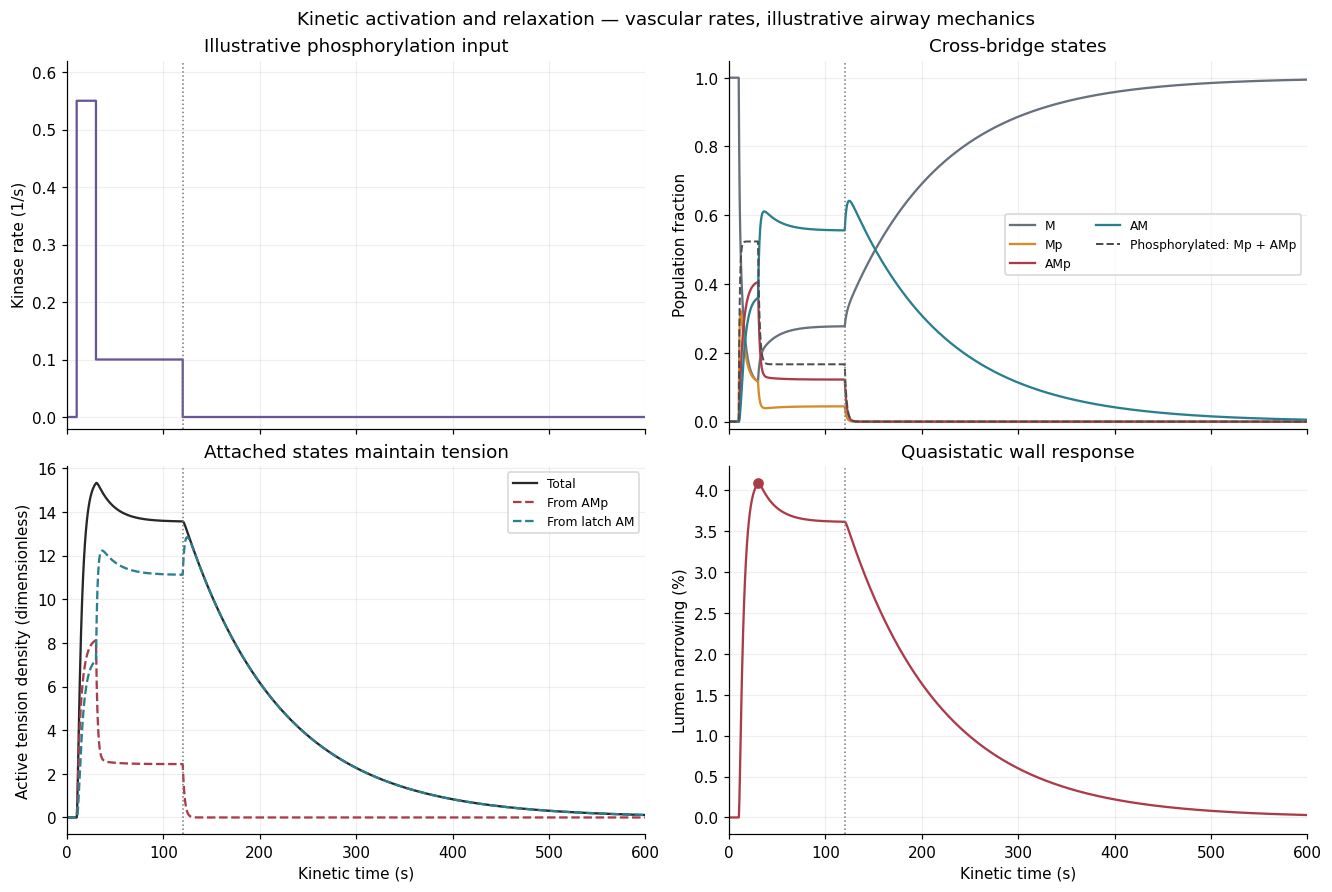

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharex=True)
colors = ["#66717d", "#d58b2a", "#aa3c49", "#287f8e"]
axes[0, 0].step(kinetic_times, protocol.values(kinetic_times), where="post", color="#6a5696")
axes[0, 0].set(ylabel="Kinase rate (1/s)", title="Illustrative phosphorylation input", ylim=(-.02, .62))
for i, (name, color) in enumerate(zip(STATE_NAMES, colors)):
    axes[0, 1].plot(kinetic_times, kinetic_states[:, i], color=color, label=name)
axes[0, 1].plot(kinetic_times, phosphorylation, "--", color="#4c4c4c", lw=1.3, label="Phosphorylated: Mp + AMp")
axes[0, 1].set(ylabel="Population fraction", title="Cross-bridge states", ylim=(-.02, 1.05))
axes[0, 1].legend(fontsize=8, ncol=2)
axes[1, 0].plot(kinetic_times, wall_timecourse["tension_density"], color="#282828", label="Total")
axes[1, 0].plot(kinetic_times, continuum_stress * kinetic_states[:, 2], "--", color=colors[2], label="From AMp")
axes[1, 0].plot(kinetic_times, continuum_stress * kinetic_states[:, 3], "--", color=colors[3], label="From latch AM")
axes[1, 0].set(xlabel="Kinetic time (s)", ylabel="Active tension density (dimensionless)", title="Attached states maintain tension")
axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(kinetic_times, wall_timecourse["narrowing_percent"], color="#aa3c49")
axes[1, 1].plot(kinetic_times[peak_index], wall_timecourse["narrowing_percent"][peak_index], "o", color="#aa3c49")
axes[1, 1].set(xlabel="Kinetic time (s)", ylabel="Lumen narrowing (%)", title="Quasistatic wall response")
for ax in axes.flat:
    ax.set_xlim(0, 600)
    ax.axvline(120, color="#777777", ls=":", lw=1)
fig.suptitle("Kinetic activation and relaxation — vascular rates, illustrative airway mechanics")
plt.show()

### Interpretation and saved evidence

Lowering kinase input reduces phosphorylation while attached dephosphorylated
bridges sustain tension. Withdrawal permits further dephosphorylation, followed
by the slower latch-detachment tail; narrowing returns toward zero. The remaining
small narrowing at 600 s is a finite-time value, not a nonzero relaxed equilibrium.

Save rates and their provenance, stimulus switches, populations, nominal tension,
lumen area, radial profiles, convergence diagnostics, reference comparison, and
refinement errors. All arrays contain accepted direct solves. The readback check
below requires a complete finite report.

In [29]:
phase4_report = {
    "schema_version": 1,
    "scope": "Four-state Hai-Murphy kinetics with one-way quasistatic symmetric wall mechanics",
    "units": {"time": "seconds", "kinetic_rates": "1/seconds", "populations": "fractions",
              "wall_geometry_moduli_tension": "dimensionless, illustrative"},
    "kinetics": {"state_order": list(STATE_NAMES), "fixed_rates": asdict(hm_rates),
                 "kinase_rule": "k1 = k6 = prescribed piecewise-constant rate",
                 "initial_state": [1, 0, 0, 0],
                 "switch_times_seconds": list(protocol.switch_times),
                 "kinase_rates_per_second": list(protocol.kinase_rates),
                 "protocol_provenance": "Illustrative, not an experimental stimulus",
                 "rate_provenance": "Hai and Murphy 1988, 255:C86-C94, pp. C86-C87; fitted swine carotid media",
                 "integrator": "Matrix exponential, split at every input switch; no population renormalization"},
    "coupling": {"tension_rule": "T = tension_scale * (AMp + AM)", "tension_scale": continuum_stress,
                 "wall_moduli": continuum_moduli, "poisson_ratio": continuum_nu,
                 "radial_intervals": working_resolution[0], "sectors": working_resolution[1],
                 "force_density_tolerance": continuum_force_tol,
                 "mechanical_clock": None, "kinetic_feedback_from_wall": False,
                 "wall_reference": "phase3_mesh_convergence.json"},
    "time_seconds": kinetic_times.tolist(), "states": kinetic_states.tolist(),
    "phosphorylation_fraction": phosphorylation.tolist(),
    "wall": {key: value.tolist() for key, value in wall_timecourse.items()},
    "published_model_comparison": {
        "reference": "C87 Eqs. 3-4 / Fig. 2A; analytic model comparison, not experimental validation",
        "kinase_rate": reference_kinase.tolist(), "stationary_states": stationary.tolist(),
        "f_reference": f_reference.tolist(), "g_reference": g_reference.tolist(),
        "f_numerical": f_numerical.tolist(), "g_numerical": g_numerical.tolist(),
        "maximum_rate_error": published_reference_error},
    "verification": {"kinetic_tests_passed": kinetic_verification.testsRun,
                     "population_sum_error": mass_error, "minimum_population": minimum_population,
                     "scalar_phosphorylation_error": phosphorylation_error,
                     "coarse_fine_common_time_population_error": common_time_error,
                     "rk4_steps_seconds": rk4_steps.tolist(), "rk4_maximum_fraction_errors": rk4_errors.tolist(),
                     "fine_spacing_seconds": {"through_160_seconds": .25, "after_160_seconds": 1.25},
                     "coarse_spacing_seconds": {"through_160_seconds": .5, "after_160_seconds": 2.5},
                     "coarse_interpolation_narrowing_error_pp": sampling_error,
                     "sampling_tolerance_pp": sampling_tolerance,
                     "independent_shared_sample_radius_error": shared_radius_error,
                     "kinetic_snapshot_mesh_checks": kinetic_mesh_checks,
                     "late_100_second_tension_ratio": late_tension_ratio},
    "summary": {"peak_sampled_time_seconds": float(kinetic_times[peak_index]),
                "peak_sampled_narrowing_percent": float(wall_timecourse["narrowing_percent"][peak_index]),
                "peak_sampled_tension_density": float(wall_timecourse["tension_density"][peak_index]),
                "final_narrowing_percent": float(wall_timecourse["narrowing_percent"][-1]),
                "accepted_wall_snapshots": len(kinetic_times)},
    "limitations": ["Vascular kinetic rates, no airway data fitting",
                    "Dimensionless wall parameters and tension scale",
                    "Quasistatic approximation; no viscosity, strain feedback, or Huxley force-velocity law",
                    "Rotationally symmetric branch; nonsymmetric stability not established",
                    "Legacy spring mesh independence not established"],
    "software": {"python": sys.version.split()[0], "numpy": np.__version__, "scipy": scipy.__version__},
    "sources": ["https://doi.org/10.1152/ajpcell.1988.255.1.C86",
                "https://doi.org/10.1152/ajpcell.1988.254.1.C99"],
}
phase4_path = results_directory / "phase4_kinetics.json"
phase4_path.write_text(json.dumps(phase4_report, indent=2, allow_nan=False) + "\n")
phase4_readback = json.loads(phase4_path.read_text())
assert len(phase4_readback["states"]) == len(kinetic_times)
assert all(phase4_readback["wall"]["converged"])
np.testing.assert_array_equal(phase4_readback["wall"]["narrowing_percent"], wall_timecourse["narrowing_percent"])
print(f"Saved kinetic and mechanical evidence to {phase4_path}")
print("Phase 4: PASS for the stated kinetic model and illustrative quasistatic coupling.")

Saved kinetic and mechanical evidence to results/phase4_kinetics.json
Phase 4: PASS for the stated kinetic model and illustrative quasistatic coupling.


## Completed scope

All four checklist phases are implemented and verified within their stated scope:
layer-specific spring mechanics, a stiffness–activation sweep, a converged
continuum reference on the symmetric branch, and time-dependent cross-bridge
kinetics driving that wall. Reports in `results/` preserve the numerical evidence.

These experiments establish internal consistency and the declared numerical
convergence checks. They do not establish an airway-calibrated constitutive law,
a measured mechanical response time, stability against asymmetric collapse, or
mesh independence of the original spring network. The browser app accompanies sections 11–12, using the same continuum wall,
kinetic transitions, and default parameters. Its prescribed-activation mode also
reproduces the continuum stiffness sweep; the earlier spring sections remain
background experiments.

## Browser companion and reproducibility

Run the app from `frontend/` with `npm install` and `npm start`. Select **Reset
defaults**, then **Run model**, to reproduce the section 12 protocol: kinase rates
0, 0.55, 0.10, and 0 per second with switches at 0, 10, 30, and 120 s. The time
course uses the same 993 output times through 600 s. Playback is labelled in
kinetic seconds and changes only the display speed. The browser magnifies radial
displacements up to 10×, with one labelled factor per run and a true-scale option
under **View & mesh**. Tissue textures are illustrative; reported areas, plots,
and exported radii remain unscaled.

Select **Prescribed activation** for the section 11 continuum equilibrium and
open **Tissue stiffness** → **Compare tissue stiffness** for its five non-muscle modulus multipliers.
At the default moduli and full prescribed activation, narrowing is 5.350553%;
the default kinetic time course peaks at 4.087249% at 30.5 s. The app shows all
four tissue regions, independent layer moduli, cross-bridge fractions, nominal
tension, lumen narrowing, and convergence diagnostics. Its JSON download records
the parameters and every accepted sample. Unfinished equilibria are rejected.

The implementations are [Python continuum](continuum.py), [Python kinetics](hai_murphy.py),
[browser continuum](../frontend/src/model/continuum.js), and
[browser kinetics](../frontend/src/model/kinetics.js). The browser integrates a
representative sector and rotates its two-dimensional nodal forces to recover
the full symmetric mesh. Its small matrix exponential uses uniformization with
scaling and squaring. These are computational choices for the same equations.

Run `npm test` from `frontend/` to compare all 11 refinement meshes, all 25
continuum sweep cases, and every kinetic state and wall profile in the 993-sample
time course with this notebook's saved reports. Additional Python fixtures test
non-default materials, geometry, rates, and switches between output times. Source
hashes require these fixtures to be regenerated after a Python model change,
using `python -m backend.export_browser_reference` from the repository root.
The tests also check limiting cases and rejected solves. Re-execute this notebook
and regenerate those fixtures whenever the reference equations or parameters change.
